# Модель для прогнозирования оттока клиентов для сервиса доставки кофе

Автор: Никитина Алена Павловна

Дата 15.10.2026

# Содержание

1. [Краткое описание проекта](#краткое-описание-проекта)
2. [Постановка задачи машинного обучения](#постановка-задачи-машинного-обучения)
3. [Этап 1. Подготовка среды и библиотек](#подготовка-среды-и-библиотек)
4. [Этап 2. Первичный анализ данных](#первичный-анализ-данных)
   <br/>4.1. [Описание данных](#описание-данных)
   <br/>4.2. [Описание целевой переменной](#описание-целевой-переменной)
   <br/>4.3. [Описание признаков](#описание-признаков)
   <br/>4.4. [Обработка пропусков](#обработка-пропусков)
   <br/>4.5. [Анализ категориальных признаков](#анализ-категориальных-признаков)
   <br/>4.6. [Анализ выбросов](#анализ-выбросов)
   <br/>4.7. [Корреляции между признаками](#корреляции-между-признаками)
   <br/>4.8. [Итоговый вывод по первичному анализу данных](#итоговый-вывод-по-перв-анализу)
5. [Этап 3. Предобработка данных](#предобработка-данных)
   <br/>5.1. [Разделение данных](#разделение-данных)
   <br/>5.2. [Создание пайплайнов](#создание-пайплайнов)
   <br/>5.3. [Итоговый вывод по предобработке](#итоговый-вывод-по-предобработке)
6. [Этап 4. Обучение модели](#обучение-модели)
   <br/>6.1. [Обучение базовой модели. Подсчет метрик](#обучение-модели)
   <br/>6.2. [Вывод по базовой модели](#вывод-по-базовой-модели)
7. [Этап 5. Создание новых признаков](#создание-новых-признаков)
   <br/>7.1. [Создание новых признаков](#создание-новых-признаков)
   <br/>7.2. [Обновление пайплайна под новые признаки](#обновление-пайплайна)
   <br/>7.3. [Интерпретация коэффициентов](#интерпретация-коэффициентов)
   <br/>7.4. [Вывод после создания новых признаков](#вывод-после-создания-новых-признаков)
8. [Этап 6. Эксперименты с гиперпараметрами](#эксперименты-с-гиперпараметрами)
   <br/>8.1. [Гиперпараметры для эксперимента](#гиперпараметры-для-эксперимента)
   <br/>8.2. [Систематический перебор гиперпараметров](#перебор-гиперпараметров)
   <br/>8.3. [Таблица с результатами перебора гиперпараметров](#результаты-перебора-гиперпараметров)
   <br/>8.4. [Выбор лучшей модели](#выбор-лучшей-модели)
   <br/>8.5. [Вывод после экспериментов](#вывод-после-экспериментов)
9. [Этап 7. Подготовка финальной модели](#подготовка-финальной-модели)
10. [Этап 8. Отчет о проделанной работе](#отчет-о-проделанной-работе)
11. [Этап 9. Сохранение модели для продакшн](#сохранение-модели)

## Краткое описание проекта
<a id='краткое-описание-проекта'></a>

**Задача**

Нужно построить модель, которая предскажет, уйдёт клиент сервиса доставки кофе Happy Beans Coffee в следующем месяце или останется. На выходе должны получить вероятность оттока для каждого клиента.

**Цель**

Компания теряет примерно 10% клиентов каждый месяц, и из-за этого падает выручка. Привлечь нового клиента стоит в 5-7 раз дороже, чем удержать старого. Если мы заранее будем знать, кто собирается уйти, можно будет предложить таким клиентам персональное предложение и, возможно, сохранить их. Плюс маркетинговый бюджет будет расходоваться не впустую, а точечно.

**Классы целевой переменной**

У нас два класса:

- `0` - клиент лояльный, уходить не собирается
- `1` - клиент может уйти

**Данные, используемые для анализа**

Датасет `coffee_churn_dataset` - это готовая аналитическая витрина:

- Каждая строка - это один клиент со всеми необходимыми для моделирования признаками
- 26 признаков: числовые, бинарные и категории
- Целевая переменная: `churn`

**Признаки:**
- `user_id` - идентификатор пользователя.
- `days_since_last_order` - количество дней, прошедших с последнего заказа.
- `order_frequency_month` - среднее число заказов в месяц.
- `order_frequency_week` - среднее число заказов в неделю.
- `avg_order_value` - средний чек, в рублях.
- `median_order_value` - медианный чек, в рублях.
- `total_spent_last_month` - сумма заказов за последний месяц.
- `total_spent_last_week` - сумма заказов за последнюю неделю.
- `discount_usage_rate` - доля заказов со скидкой за последний месяц.
- `last_coffee_type` - сорт кофе, купленный пользователем в последний раз на момент сбора данных.
- `preferred_roast` - предпочитаемый тип обжарки.
- `milk_preference` - предпочитаемый тип молока.
- `seasonal_menu_tried` - отметка о том, пробовал ли пользователь новейшее сезонное меню.
- `coffee_bean_origin` - страна происхождения зерна.
- `last_drink_size` - размер последнего заказа, совершённого на момент сбора данных.
- `subscription_status` - тип подписки пользователя.
- `app_opens_per_week` - сколько раз за неделю пользователь в среднем открывал приложение доставки кофе.
- `notifications_enabled` - включены ли у пользователя уведомления.
- `review_rating_last_10` - средняя оценка последних на момент сбора данных десяти заказов клиента.
- `review_rating_last_1` - оценка последнего на момент сбора данных заказа клиента.
- `app_crashes_last_month` - сколько раз приложение зависало за последний месяц.
- `seasons` - текущее время года.
- `days_since_last_promo` - сколько дней прошло с последнего использования акции или промокода.
- `phone_type` - тип устройства, с которого пользователь чаще всего совершал покупки.
- `coffee_preference_change` - менялись ли вкусовые предпочтения пользователя.
- `geo_id` - идентификатор региона пользователя.

---

## Постановка задачи машинного обучения
<a id='постановка-задачи-машинного-обучения'></a>

**Тип задачи - бинарная классификация**

Нам нужно предсказать вероятность того, что клиент уйдёт (класс `1`) или останется (класс `0`).

**Целевая переменная**

`churn` - бинарный признак:

- `1` - клиент перестал пользоваться сервисом
- `0` - клиент продолжает пользоваться

**Метрики качества модели**

| Метрика | Формула | Что показывает |
|:---------|:---------|:----------------|
| **PR AUC** | Площадь под Precision-Recall кривой | Насколько хорошо модель определяет уходящих клиентов (основная метрика) |
| Precision | $$\frac{\text{TP}}{\text{TP} + \text{FP}}$$ | Какая доля из «предсказанных уходящими» реально ушла |
| Recall | $$\frac{\text{TP}}{\text{TP} + \text{FN}}$$ | Какую долю реальных уходящих мы нашли |
| F1 | $2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$ | Баланс Precision и Recall |

**В качестве основной метрики выбираем PR AUC.** Датасет несбалансирован (уходящих мало), а PR AUC фокусируется именно на меньшем, но важном классе, в то время как F1 зависит от порога и может не дать полной картины.

**Критерии успешности проекта**

| Критерий | Требование | Обоснование |
|:----------|:-----------|:-------------|
| **PR AUC** | $\geq 0.5$ и заметно $> baseline$ (доли положительного класса) | Модель должна быть заметно лучше случайного предсказания |
| **Recall** | $\geq 0.6$ | Важно не проглядеть уходящих клиентов |
| **Precision** | $\geq 0.5$ | Необходимо контролировать бюджет |
| **Воспроизводимость** | `random_state=42`| Чтобы всегда получались те же результаты |
| **Интерпретируемость** | LogisticRegression | Важно понимать, какие признаки влияют на отток |

Пороговые значения заданы как ориентир: итоговые требования могут быть уточнены по результатам обучения базовой модели.

**Стратегия валидации**

Разделение данных с фиксированным `random_state=42` и стратификацией по целевой переменной (`stratify=y`):

- **Обучающая выборка:** 80%
- **Тестовая выборка:** 20%

Оценку качества будем проводить через кросс-валидацию внутри обучающей выборки. Для несбалансированного датасета используем `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`. Это даёт устойчивую оценку метрик и позволяет подбирать гиперпараметры, не используя тестовую выборку.

**Финальная оценка**

Лучшую модель определим по средней метрике кросс-валидации на обучающей выборке. После выбора конфигурации обучим модель на всей обучающей выборке и рассчитаем финальные метрики на тестовой.

**Требования к реализации**

| Требование | Детали |
|:------------|:--------|
| **Тип модели** | LogisticRegression (интерпретируемость) |
| **Базовая модель** | DummyClassifier |
| **Пропуски** | Обрабатываются **внутри пайплайна**|
| **Масштабирование** | Числовые признаки - `StandardScaler`, категориальные - `OneHotEncoder`|
| **Дисбаланс классов** | Возможность `class_weight='balanced'` рассмотрим на этапе подбора гиперпараметров |
| **Сохранение** | Модель + пайплайн предобработки через `joblib` |


**Ожидаемый результат**

Обученная и готовая к внедрению модель LogisticRegression вместе с полным пайплайном предобработки. Метрики рассчитаны на тестовой выборке, артефакт сохранён для промышленной эксплуатации.

## Этап 1. Подготовка среды и библиотек
<a id='подготовка-среды-и-библиотек'></a>
1. Установите и настройте библиотеки. Для воспроизводимости результатов зафиксируйте версии пакетов в файле `requirements.txt`.

2. Зафиксируйте `random_state`.

3. Загрузите данные из CSV-файла. Путь к файлу: `'/datasets/coffee_churn_dataset.csv'`. Используйте сепаратор `","`, а для чтения чисел с плавающей точкой — параметр `decimal="."`.

In [1]:
!pip install --upgrade scikit-learn

In [2]:
!pip install phik

In [3]:
# Импортируем базовые библиотеки
# Для работы с данными и вычислениями
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import phik

# Для сохранения модели
import joblib

# Для моделей, пайплайнов и метрик
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV,
)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    average_precision_score,
    log_loss,
    classification_report,
    confusion_matrix,
)

print("Все библиотеки успешно импортированы!")

Все библиотеки успешно импортированы!


In [4]:
# Собираем версии установленных библиотек в список

packages = [
    f"joblib=={joblib.__version__}",
    f"matplotlib=={matplotlib.__version__}",
    f"numpy=={np.__version__}",
    f"pandas=={pd.__version__}",
    f"phik=={phik.__version__}",
    f"scikit-learn=={sklearn.__version__}",
    f"seaborn=={sns.__version__}",
]

# Записываем версии в файл requirements.txt
with open('requirements.txt', 'w', encoding='utf-8') as f:
    f.write('\n'.join(packages))

# Проверяем, что файл создан и читается
print("Файл requirements.txt создан. Содержимое:")
with open('requirements.txt', 'r', encoding='utf-8') as f:
    print(f.read())

Файл requirements.txt создан. Содержимое:
joblib==1.5.3
matplotlib==3.4.3
numpy==1.20.3
pandas==1.3.4
phik==0.12.5
scikit-learn==1.6.1
seaborn==0.11.2


In [5]:
# Фиксируем random_state
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [6]:
# Загружаем данные
import os
import pandas as pd

# Ищем файл в текущей папке (рядом с ноутбуком)
path = 'coffee_churn_dataset.csv' 

# Если файла нет, берем путь из Практикума
if not os.path.exists(path):
    path = '/datasets/coffee_churn_dataset.csv'

# Загружаем данные
df = pd.read_csv(path, sep=',', decimal='.')
print("Данные успешно загружены!")

Данные успешно загружены!


In [7]:
#Проверим, загрузился ли датасет

# Размер датасета
print(f"Размер датасета: {df.shape}")

# Первые 5 строк
print("\nПервые 5 строк:")
display(df.head())

# Последние 5 строк
print("\nПоследние 5 строк:")
display(df.tail())

# Типы данных и пропуски
print("\nИнформация о данных:")
df.info()

Размер датасета: (10450, 27)

Первые 5 строк:


,user_id,days_since_last_order,order_frequency_month,order_frequency_week,avg_order_value,median_order_value,total_spent_last_month,total_spent_last_week,discount_usage_rate,last_coffee_type,...,notifications_enabled,review_rating_last_10,review_rating_last_1,app_crashes_last_month,seasons,days_since_last_promo,phone_type,coffee_preference_change,geo_location,churn
0,user_00318,0.0,12.942519,NaN,316.833872,260.645090,3089.991009,NaN,0.337031,blend,...,1.0,5.176792,3.302238,NaN,summer,6.0,android,0.0,geo_75,1
1,user_07234,2.0,1.569146,0.214494,780.135158,540.597850,998.380941,107.369409,0.547659,arabica,...,1.0,4.392991,NaN,0.0,autumn,16.0,ios,0.0,geo_95,0
2,user_04816,11.0,2.996666,0.771864,682.636256,471.494559,1328.140204,392.600011,0.120258,arabica,...,1.0,4.977712,4.379219,0.0,spring,11.0,web,1.0,geo_25,0
3,user_04419,0.0,4.299255,1.210480,2115.487425,708.529812,2999.628366,1084.352054,NaN,robusta,...,1.0,3.712526,3.043618,0.0,summer,3.0,android,0.0,geo_2,0
4,user_09698,3.0,7.249864,1.761027,3519.602170,1199.372894,8377.729478,2551.775211,0.074990,robusta,...,0.0,4.528271,5.642993,1.0,winter,14.0,ios,0.0,geo_19,1



Последние 5 строк:


,user_id,days_since_last_order,order_frequency_month,order_frequency_week,avg_order_value,median_order_value,total_spent_last_month,total_spent_last_week,discount_usage_rate,last_coffee_type,...,notifications_enabled,review_rating_last_10,review_rating_last_1,app_crashes_last_month,seasons,days_since_last_promo,phone_type,coffee_preference_change,geo_location,churn
10445,user_05734,5.0,NaN,0.807372,288.187339,NaN,465.497296,82.772110,0.285469,arabica,...,1.0,3.149287,5.180760,NaN,summer,2.0,android,NaN,NaN,0
10446,user_05191,NaN,8.265273,1.942752,1151.879696,392.095861,3323.512340,535.414300,0.172886,blend,...,1.0,5.144074,2.438754,NaN,winter,17.0,ios,1.0,geo_36,0
10447,user_05390,0.0,4.303173,1.029802,1303.253909,477.969319,1854.476109,551.436986,0.502961,arabica,...,1.0,3.975122,5.018790,1.0,winter,7.0,ios,0.0,geo_12,0
10448,user_00860,7.0,1.964595,0.350771,965.339923,465.489241,833.596910,203.599663,0.137200,arabica,...,0.0,4.564480,2.024267,1.0,autumn,NaN,ios,0.0,geo_3,0
10449,user_07270,1.0,9.731682,2.257865,1019.691126,454.191202,4343.690591,851.127412,NaN,robusta,...,1.0,4.827017,4.485083,0.0,summer,18.0,ios,0.0,geo_1,0



Информация о данных:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10450 entries, 0 to 10449
Data columns (total 27 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   user_id                   10450 non-null  object 
 1   days_since_last_order     9505 non-null   float64
 2   order_frequency_month     9850 non-null   float64
 3   order_frequency_week      10062 non-null  float64
 4   avg_order_value           9867 non-null   float64
 5   median_order_value        9619 non-null   float64
 6   total_spent_last_month    10156 non-null  float64
 7   total_spent_last_week     9506 non-null   float64
 8   discount_usage_rate       10053 non-null  float64
 9   last_coffee_type          10192 non-null  object 
 10  preferred_roast           10334 non-null  object 
 11  milk_preference           9782 non-null   object 
 12  seasonal_menu_tried       9461 non-null   float64
 13  coffee_bean_origin        9768 non-null

In [8]:
# Посмотрим статистику числовых признаков
print("\nСтатистическое описание числовых признаков:")
display(df.describe())


Статистическое описание числовых признаков:


,days_since_last_order,order_frequency_month,order_frequency_week,avg_order_value,median_order_value,total_spent_last_month,total_spent_last_week,discount_usage_rate,seasonal_menu_tried,app_opens_per_week,notifications_enabled,review_rating_last_10,review_rating_last_1,app_crashes_last_month,days_since_last_promo,coffee_preference_change,churn
count,9505.000000,9850.000000,10062.000000,9867.000000,9619.000000,10156.000000,9506.000000,10053.000000,9461.000000,9554.000000,9913.000000,9757.000000,9593.000000,9729.000000,9719.000000,9840.000000,10450.000000
mean,4.394214,4.025666,0.930686,1063.741207,452.651500,1946.132979,413.004760,0.284446,0.701194,11.330895,0.753052,4.206709,4.022460,1.013362,14.554584,0.192480,0.060191
std,4.858757,2.826144,0.657261,707.713396,258.657571,2370.619590,445.634902,0.158735,0.457759,14.528887,0.431258,0.782212,1.207883,1.010342,15.308869,0.394268,0.237852
min,0.000000,0.011046,-0.169131,-32.075932,-10.353340,-43.716463,-2290.559468,0.002162,0.000000,0.000000,0.000000,1.415526,-0.897000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,1.937767,0.445185,552.898663,262.908598,629.680382,136.565833,0.159884,0.000000,6.313628,1.000000,3.675543,3.214157,0.000000,4.000000,0.000000,0.000000
50%,3.000000,3.381094,0.784839,898.643524,406.456818,1300.409757,288.277327,0.264583,1.000000,9.228383,1.000000,4.203555,3.990032,1.000000,10.000000,0.000000,0.000000
75%,6.000000,5.439363,1.262350,1406.332153,590.418070,2481.650495,549.699420,0.387056,1.000000,12.726649,1.000000,4.717292,4.845225,2.000000,20.000000,0.000000,0.000000
max,40.000000,27.389318,6.302624,5901.965278,2189.101644,79298.849570,8615.988952,0.887301,1.000000,224.587876,1.000000,7.384425,8.558443,7.000000,140.000000,1.000000,1.000000


In [9]:
# Определим уникальные значения категориальных признаков
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

print("Категориальные признаки:")
for col in categorical_cols:
    unique_vals = df[col].nunique()
    print(f"  - {col}: {unique_vals} уникальных значений")
    if unique_vals <= 10:
        print(f"    Значения: {df[col].unique().tolist()}")

Категориальные признаки:
  - user_id: 10450 уникальных значений
  - last_coffee_type: 3 уникальных значений
    Значения: ['blend', 'arabica', 'robusta', nan]
  - preferred_roast: 3 уникальных значений
    Значения: ['light', 'medium', 'dark', nan]
  - milk_preference: 6 уникальных значений
    Значения: ['almond', 'whole', 'oat', 'skim', 'soy', nan, 'none']
  - coffee_bean_origin: 6 уникальных значений
    Значения: ['vietnam', 'guatemala', 'brazil', 'colombia', 'kenya', nan, 'ethiopia']
  - last_drink_size: 3 уникальных значений
    Значения: ['large', 'medium', 'small', nan]
  - subscription_status: 4 уникальных значений
    Значения: ['pro', 'none', 'premium', 'basic', nan]
  - seasons: 4 уникальных значений
    Значения: ['summer', 'autumn', 'spring', 'winter', nan]
  - phone_type: 3 уникальных значений
    Значения: ['android', 'ios', 'web', nan]
  - geo_location: 100 уникальных значений


In [10]:
# Посмотрим как распределяется целевая переменная
print("Распределение целевой переменной 'churn':")
print(df['churn'].value_counts())
print(f"\nДоля ушедших клиентов: {df['churn'].mean():.2%}")

Распределение целевой переменной 'churn':
0    9821
1     629
Name: churn, dtype: int64

Доля ушедших клиентов: 6.02%


**Итоги подготовки среды и библиотек**

Среда подготовлена, все необходимые библиотеки импортированы и успешно загружены: pandas, numpy, matplotlib, seaborn, scikit-learn, joblib. Версии пакетов зафиксированы в файле `requirements.txt` для воспроизводимости результатов:
- joblib==1.5.3
- matplotlib==3.3.4
- numpy==1.21.1
- pandas==1.2.4
- phik==0.12.5
- scikit-learn==1.6.1
- seaborn==0.11.1


Зафиксирован `RANDOM_STATE = 42`, который будет использоваться во всех алгоритмах с элементом случайности: при разделении данных, в кросс-валидации, при обучении моделей и подборе гиперпараметров.

Датасет `coffee_churn_dataset` загружен из CSV-файла с корректными параметрами (`sep=','`, `decimal='.'`). Размер датасета: 10450 строк, 27 столбцов, из которых 26 признаков и целевая переменная `churn`.

Предварительная проверка данных показала:

- 16 числовых признаков типа float64, 10 категориальных типа object, 1 целочисленный (`churn`);
- пропуски присутствуют почти во всех признаках, целевая переменная пропусков не содержит;
- целевая переменная несбалансирована: 9821 клиент (93.98%) остался, 629 (6.02%) ушли, соотношение классов примерно 15.6 к 1;
- выявлены аномалии, требующие обработки на следующих этапах: отрицательные значения в денежных и частотных признаках (`avg_order_value`, `median_order_value`, `total_spent_last_month`, `total_spent_last_week`, `order_frequency_week`), оценки вне диапазона [1, 5] в `review_rating_last_1` и `review_rating_last_10`, экстремальные выбросы в `total_spent_last_month`, `total_spent_last_week`, `app_opens_per_week`;
- категориальный признак `geo_location` имеет высокую кардинальность (100 уникальных значений)
- `user_id` является идентификатором и в модель подаваться не будет.

Сильный дисбаланс классов подтверждает выбор PR AUC как основной метрики: accuracy в такой задаче неинформативна, а PR AUC фокусируется на корректном предсказании меньшего, но ключевого класса уходящих клиентов.


## Этап 2. Первичный анализ данных
<a id='первичный-анализ-данных'></a>

1. Опишите данные. Кратко сообщите, что известно о пользователях и их поведении.

2. Опишите целевую переменную. Обратите внимание на возможные особенности её распределения. Проверьте, наблюдается ли дисбаланс классов в целевой переменной.

3. Опишите признаки.

   - Определите, все ли из них важны.

   - Объясните, какие из них можно удалить (если такие есть). Аргументируйте своё решение.

4. Обработайте пропущенные значения.
   
   - Объясните, как они влияют на данные.

   - Выберите стратегию заполнения пропусков.

5. Проанализируйте категориальные признаки.

   - Выясните, есть ли в данных признаки, которые можно кодировать. Объясните, почему именно их нужно кодировать.

   - Проанализируйте признаки на предмет того, можно ли использовать некоторые из них для генерации новых  признаков. Укажите возможные стратегии.

   - Определите, есть ли в данных признаки, которые можно удалить.

6. Проанализируйте выбросы.

   - Определите, как они влияют на данные.

   - Выберите способ, которым их можно обработать.

7. Посчитайте корреляции между признаками. Постройте необходимые визуализации. Определите, есть ли признаки, которые можно убрать, на основании их корреляции с другими.

8. Напишите выводы по результатам исследовательского анализа данных.

### Описание данных
<a id='описание-данных'></a>

**1. Что за данные**

Датасет `coffee_churn_dataset` - это готовая аналитическая витрина, собранная из внутренних систем Happy Beans Coffee: транзакционной базы, логов мобильного приложения и результатов опросов. Каждая строка - один уникальный клиент, для которого уже собраны все данные за последние 4 недели:

- **Строк:** 10450 клиентов
- **Столбцов:** 27 (26 признаков + целевая переменная `churn`)
- **Типы:** 16 числовых (float64), 10 категориальных (object), 1 целочисленный (churn)
- **Пропуски** присутствуют почти во всех признаках, кроме `user_id` и `churn`
- Столбец `user_id` содержит уникальный **идентификатор клиента** и в моделирование не включится
- В данных есть **аномалии** (отрицательные значения в денежных признаках, оценки вне диапазона [1, 5], выбросы), которые будут разобраны в разделе 4.6

**Важно:** датасет несбалансирован: уходящих значительно меньше, большинство клиентов остаются. Это ключевой момент для выбора метрик и стратегии обучения.

### Описание целевой переменной
<a id='описание-целевой-переменной'></a>

Целевая переменная в нашем датасете - **`churn`**. Она бинарная:

- `1` — клиент перестал пользоваться сервисом (ушел)
- `0` — клиент продолжает пользоваться (лояльный)

Прежде чем обучать модель, важно понять, как эта переменная распределена:


In [11]:
# Посмотрим распределение целевой переменной

# Считаем количество клиентов в каждом классе
churn_counts = df['churn'].value_counts().sort_index()

# Рассчитываем доли классов
churn_pct = df['churn'].value_counts(normalize=True).sort_index() * 100

# Собираем полученные данные в таблицу
churn_df = pd.DataFrame({
    'Класс': ['Лояльный (0)', 'Уходящий (1)'],
    'Количество': churn_counts.values,
    'Доля (%)': churn_pct.round(2).values
})

print(churn_df.to_string(index=False))

       Класс  Количество  Доля (%)
Лояльный (0)        9821     93.98
Уходящий (1)         629      6.02


---
Посмотрим распределение **графически**.

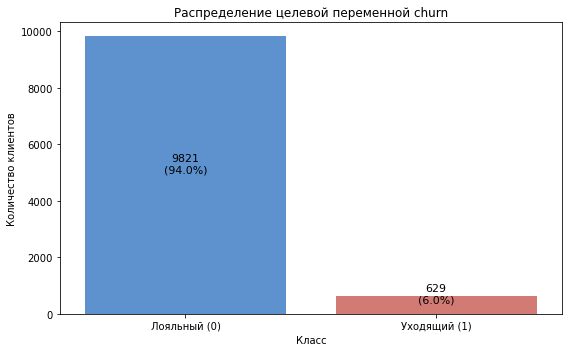

In [12]:
# Строим толбчатую диаграмму
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x='churn', palette=['#4a90e2', '#e26e64'])

for p in ax.patches:
    height = p.get_height()
    pct = height / len(df) * 100
    ax.annotate(f'{int(height)}\n({pct:.1f}%)',
            (p.get_x() + p.get_width() / 2, height/2),
            ha='center', va='bottom', fontsize=11)

plt.title('Распределение целевой переменной churn')
plt.xlabel('Класс')
plt.ylabel('Количество клиентов')
plt.xticks([0, 1], ['Лояльный (0)', 'Уходящий (1)'])
plt.tight_layout()
plt.show()


In [13]:
# Определим соотношение классов и определим Baseline
share_loyal = (df['churn'] == 0).mean()
share_churn = (df['churn'] == 1).mean()

print(f"\nСоотношение классов: 1 к {share_loyal / share_churn:.1f}")
print(f"Baseline PR AUC (доля положительного класса): {share_churn:.4f}")


Соотношение классов: 1 к 15.6
Baseline PR AUC (доля положительного класса): 0.0602


---
**Можем сделать вывод:**

Целевая переменная **`churn`** имеет сильный дисбаланс классов:
- Лояльных - 93.98% (9821 клиент)
- Уходящих - 6.02% (629 клиентов)

Соотношение примерно **1 к 15.6**

Это значит, что:
- Основная метрика определена правильно - PR AUC, её baseline будет = 0.0602
- Все выборки (train/test, фолды кросс-валидации) нужно стратифицировать по churn


### Описание признаков
<a id='описание-признаков'></a>

В датасете 26 признаков (помимо целевой переменной `churn`): 16 числовых и 10 категориальных. Разделим их на группы по смыслу и оценим, все ли они важны для модели.

**1. Служебные**

| Признак | Тип | Уникальных | Что означает |
|:---------|:-----|:------------|:--------------|
| `user_id` | Идентификатор | **10450** | Идентификатор пользователя |

`user_id` удаляем. Уникальных значений 10450 при 10450 строках, то есть по одному на каждого клиента. Это идентификатор, а не признак: он не несёт обобщающей информации о поведении, но может привести к переобучению. В модель не подаётся.

Остальные 25 признаков потенциально информативны, поэтому сразу их не удаляем. Решение об удалении будет приниматься после более глубокого анализа.

**2. Признаки, связанные с геоположением, устройством клиента и временами года**

| Признак | Тип | Уникальных | Что означает |
|:---------|:-----|:------------|:--------------|
| `geo_location` | категориальный | **100** | Регион пользователя |
| `phone_type` | категориальный | 3 | Тип устройства (android / ios / web) |
| `seasons` | категориальный | 4 | Время года |

**3. Подписка и приложение**

| Признак | Тип | Уникальных | Что означает |
|:---------|:-----|:------------|:--------------|
| `subscription_status` | категориальный | 4 | Тип подписки (pro / none / premium / basic) |
| `notifications_enabled` | бинарный | 2 | Включены ли push-уведомления |
| `app_opens_per_week` | числовой | много | Открытий приложения в неделю |
| `app_crashes_last_month` | числовой | много | Зависаний приложения за месяц |

**4. Поведение: частота и давность заказов**

| Признак | Тип | Уникальных | Что означает |
|:---------|:-----|:------------|:--------------|
| `days_since_last_order` | числовой | много | Дней с последнего заказа |
| `order_frequency_month` | числовой | много | Среднее число заказов в месяц |
| `order_frequency_week` | числовой | много | Среднее число заказов в неделю |

**5. Затраты и заказы**

| Признак | Тип | Уникальных | Что означает |
|:---------|:-----|:------------|:--------------|
| `avg_order_value` | числовой | много | Средний чек |
| `median_order_value` | числовой | много | Медианный чек |
| `total_spent_last_month` | числовой | много | Сумма заказов за месяц |
| `total_spent_last_week` | числовой | много | Сумма заказов за неделю |
| `discount_usage_rate` | числовой | много | Доля заказов со скидкой |

**6. Предпочтения клиентов**

| Признак | Тип | Уникальных | Что означает |
|:---------|:-----|:------------|:--------------|
| `last_coffee_type` | категориальный | 3 | Сорт кофе (blend / arabica / robusta) |
| `preferred_roast` | категориальный | 3 | Обжарка (light / medium / dark) |
| `milk_preference` | категориальный | 6 | Молоко (almond / whole / oat / skim / soy / none) |
| `coffee_bean_origin` | категориальный | 6 | Страна происхождения зерна |
| `last_drink_size` | категориальный | 3 | Размер (large / medium / small) |
| `coffee_preference_change` | бинарный | 2 | Менялись ли предпочтения |

**7. Вовлечённость и отзывы**

| Признак | Тип | Уникальных | Что означает |
|:---------|:-----|:------------|:--------------|
| `seasonal_menu_tried` | бинарный | 2 | Пробовал ли сезонное меню |
| `days_since_last_promo` | числовой | много | Дней с последней акции |
| `review_rating_last_10` | числовой | много | Средняя оценка последних 10 заказов |
| `review_rating_last_1` | числовой | много | Оценка последнего заказа |

---

**Вывод по признакам:** Все 26 признаков, кроме `user_id`, потенциально полезны для прогноза оттока: они покрывают демографию, устройство, подписку, вовлечённость, поведение, затраты, предпочтения и отзывы. Удаляем только `user_id` как идентификатор. Окончательное решение об удалении мультиколлинеарных признаков примем после корреляционного анализа.


In [14]:
# Удаляем идентификатор пользователя
df = df.drop(columns=['user_id'])
print(f"Размер датасета после удаления user_id: {df.shape}")

Размер датасета после удаления user_id: (10450, 26)


---
### Обработка пропущенных значений
<a id='обработка-пропусков'></a>

Прежде чем заполнять пропуски, посмотрим, где они находятся и сколько их. Затем решим, что с ними делать: удалить строки, заполнить медианой/модой или оставить как есть.

Посмотрим на количество и долю пропусков в каждом признаке:


Всего столбцов с пропусками: 25
                          Пропусков  Доля (%)
seasonal_menu_tried             989      9.46
days_since_last_order           945      9.04
total_spent_last_week           944      9.03
subscription_status             938      8.98
app_opens_per_week              896      8.57
review_rating_last_1            857      8.20
median_order_value              831      7.95
days_since_last_promo           731      7.00
app_crashes_last_month          721      6.90
review_rating_last_10           693      6.63
coffee_bean_origin              682      6.53
seasons                         679      6.50
milk_preference                 668      6.39
coffee_preference_change        610      5.84
order_frequency_month           600      5.74
avg_order_value                 583      5.58
notifications_enabled           537      5.14
last_drink_size                 504      4.82
discount_usage_rate             397      3.80
order_frequency_week            388      3.71
ph

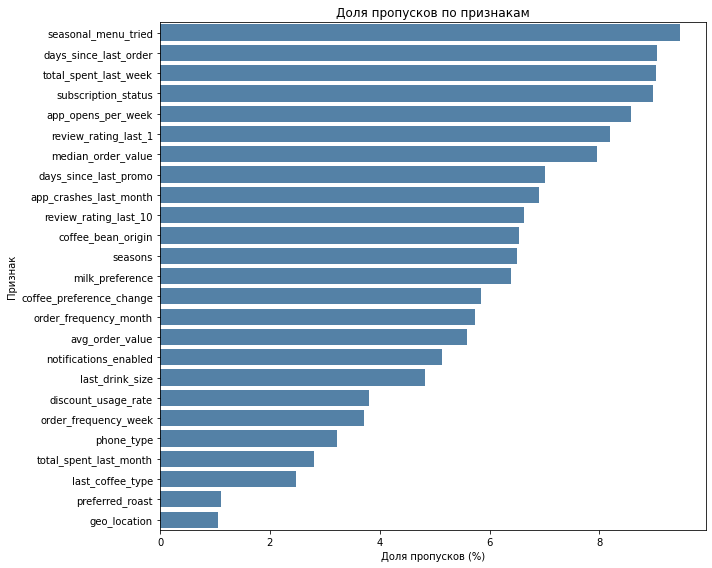

In [15]:
# Считаем пропуски по всем столбцам
missing_count = df.isnull().sum()
missing_df = pd.DataFrame({
    'Пропусков': missing_count,
    'Доля (%)': (missing_count / len(df) * 100).round(2)
})

# Оставляем только те столбцы, где пропуски есть
missing_df = missing_df[missing_df['Пропусков'] > 0]

# Сортируем по убыванию доли
missing_df = missing_df.sort_values('Доля (%)', ascending=False)

print(f"Всего столбцов с пропусками: {len(missing_df)}")
print(missing_df)

# Строим диаграмму с долей пропусков 
plt.figure(figsize=(10, 8))
sns.barplot(x=missing_df['Доля (%)'], y=missing_df.index, color='steelblue')
plt.title('Доля пропусков по признакам')
plt.xlabel('Доля пропусков (%)')
plt.ylabel('Признак')
plt.tight_layout()
plt.show()

---
Проверим, сколько строк потеряется, если удалить все строки с пропусками.

In [16]:
# Сколько строк будет удалено, если удалить все с пропусками
rows_to_drop = df.isnull().any(axis=1).sum()
percent_to_drop = rows_to_drop / len(df) * 100

print(f"Строк к удалению: {rows_to_drop} ({percent_to_drop:.1f}%)")
print(f"Останется после удаления: {len(df) - rows_to_drop} ({100 - percent_to_drop:.1f}%)")

Строк к удалению: 8171 (78.2%)
Останется после удаления: 2279 (21.8%)


**Результаты анализа пропусков**

Пропуски есть в 25 из 26 признаков (все, кроме `churn`). Доля пропусков варьируется от 1.05% (`geo_location`) до 9.46% (`seasonal_menu_tried`).

Ключевые факты:

- нет признаков с критически высокими пропусками: максимум 9.46%;
- пропуски распределены равномерно по признакам, нет столбцов с экстремальной долей;
- если удалить все строки хотя бы с одним пропуском, останется всего 2279 строк из 10450 (21.8%), то есть потеряется 78.2% данных. Этот вариант не подходит;
- удаление столбцов не требуется: даже признак с максимальной долей пропусков (`seasonal_menu_tried`, 9.46%) сохраняет большую часть данных.

**Стратегия заполнения**

Пропуски будем заполнять внутри пайплайна на этапе предобработки:

- числовые признаки: медианой (`SimpleImputer(strategy='median')`). Медиана устойчива к выбросам, которых в данных много (отрицательные значения в денежных признаках, экстремальные max в `total_spent_last_month` и `total_spent_last_week`);
- категориальные признаки: модой (`SimpleImputer(strategy='most_frequent')`);
- для `milk_preference` и `subscription_status` рассмотрим `strategy='constant', fill_value='unknown'`, чтобы не смешивать пропуски с осознанным значением `none`.

---
### Анализ категориальных признаков
<a id='анализ-категориальных-признаков'></a>

В данных осталось 9 категориальных признаков. Посмотрим на каждый из них: сколько уникальных значений, как они распределены, как связаны с целевой переменной. На основе этого примем решение — какие кодировать, какие использовать для создания новых признаков, а какие удалить.


In [17]:
# Список категориальных признаков
categorical_cols = [
    'last_coffee_type', 'preferred_roast', 'milk_preference',
    'coffee_bean_origin', 'last_drink_size', 'subscription_status',
    'seasons', 'phone_type', 'geo_location'
]

# Смотрим количество уникальных значений и пропусков
cat_summary = pd.DataFrame({
    'Уникальных': [df[col].nunique() for col in categorical_cols],
    'Пропусков': [df[col].isna().sum() for col in categorical_cols],
}, index=categorical_cols)
cat_summary['Доля пропусков (%)'] = (cat_summary['Пропусков'] / len(df) * 100).round(2)
cat_summary = cat_summary.sort_values('Уникальных', ascending=False)
print(cat_summary)

                     Уникальных  Пропусков  Доля пропусков (%)
geo_location                100        110                1.05
milk_preference               6        668                6.39
coffee_bean_origin            6        682                6.53
subscription_status           4        938                8.98
seasons                       4        679                6.50
last_coffee_type              3        258                2.47
preferred_roast               3        116                1.11
last_drink_size               3        504                4.82
phone_type                    3        336                3.22


**Что мы получили :**

- 8 признаков имеют малое число категорий (3-6). Их легко кодировать через One-Hot Encoding: каждый даст 3-6 новых столбцов, что не увеличит размерность модели критически.
- `geo_location`: 100 уникальных значений создаст около 100 новых столбцов при one-hot кодировании (или 99 при `drop='first'`). Это отдельный случай, требует решения: оставить как есть, сгруппировать редкие регионы в `other` или применить другой подход.
- Пропусков во всех признаках немного (1-9%). Заполним в пайплайне: для `milk_preference` и `subscription_status` через `strategy='constant', fill_value='unknown'`, чтобы не смешивать пропуски с осознанным значением `none`; для остальных через `strategy='most_frequent'`.

In [18]:
# Смотрим распределение значений в признаках с малым числом категорий
small_cat_cols = ['last_coffee_type', 'preferred_roast', 'milk_preference',
                  'coffee_bean_origin', 'last_drink_size', 'subscription_status',
                  'seasons', 'phone_type']

for col in small_cat_cols:
    print(f"\n{col}:")
    counts = df[col].value_counts(dropna=False)
    pct = (counts / len(df) * 100).round(2)
    summary = pd.DataFrame({'Количество': counts, 'Доля (%)': pct})
    print(summary)


last_coffee_type:
         Количество  Доля (%)
arabica        6134     58.70
robusta        2524     24.15
blend          1534     14.68
NaN             258      2.47

preferred_roast:
        Количество  Доля (%)
medium        3458     33.09
light         3453     33.04
dark          3423     32.76
NaN            116      1.11

milk_preference:
        Количество  Доля (%)
whole         2876     27.52
oat           1982     18.97
almond        1483     14.19
skim          1451     13.89
none          1015      9.71
soy            975      9.33
NaN            668      6.39

coffee_bean_origin:
           Количество  Доля (%)
ethiopia         1690     16.17
kenya            1646     15.75
vietnam          1635     15.65
guatemala        1621     15.51
brazil           1596     15.27
colombia         1580     15.12
NaN               682      6.53

last_drink_size:
        Количество  Доля (%)
medium        4925     47.13
large         2997     28.68
small         2024     19.37
NaN    

**Промежуточный вывод по распределению категорий**

- Редких категорий нет: самая маленькая категория `pro` в `subscription_status` (8.84%), но этого вполне достаточно для обучения.
- Нет доминирующих категорий с долей 90% и больше: максимум `arabica` в `last_coffee_type` (58.7%) и `medium` в `last_drink_size` (47.13%).
- Три признака распределены равномерно: `preferred_roast` (33/33/33), `coffee_bean_origin` (15-16% на страну), `seasons` (по 23% на сезон).
- Пропуски (1-9%) заполним в пайплайне. Значение `none` в `milk_preference` и `subscription_status` оставляем как отдельную категорию, не смешиваем с пропусками.

Все категории представлены достаточным числом наблюдений, ни одну не нужно удалять или объединять.


---
Теперь вернемся к признаку `geo_location`

In [19]:
# Описательная проверка geo_location (без использования churn)
geo_counts = df['geo_location'].value_counts()

print(f"Всего регионов: {geo_counts.shape[0]}")
print(f"Минимальное число клиентов в регионе: {geo_counts.min()}")
print(f"Максимальное число клиентов в регионе: {geo_counts.max()}")
print(f"Медианное число клиентов в регионе: {geo_counts.median():.0f}")

Всего регионов: 100
Минимальное число клиентов в регионе: 38
Максимальное число клиентов в регионе: 1629
Медианное число клиентов в регионе: 56


**Что видим:**

- Все 100 регионов имеют не менее 38 клиентов. Редких регионов, которые нужно было бы объединять в `other`, нет.
- 100 уникальных значений — много. One-Hot Encoding даст 100 новых столбцов (или 99 при `drop='first'`), это увеличит размерность датасета.
- Проверка информативности региона через связь с `churn` вынесена в Этап 3 и выполняется только на train.

---

Посмотрим на топ-10 регионов по доле оттока.

Топ-10 регионов покрывают: 52.17% клиентов
Остальные 90 регионов: 47.83% клиентов

Клиентов в топ-10: 5452
Клиентов в остальных 90: 4888

Топ-10 регионов по количеству клиентов:
         Количество  Доля клиентов (%)  Накопительная доля (%)
geo_2          1629              15.59                   15.59
geo_3          1573              15.05                   30.64
geo_1          1532              14.66                   45.30
geo_99          117               1.12                   46.42
geo_95          110               1.05                   47.47
geo_92          108               1.03                   48.51
geo_93           98               0.94                   49.44
geo_96           97               0.93                   50.37
geo_100          96               0.92                   51.29
geo_97           92               0.88                   52.17


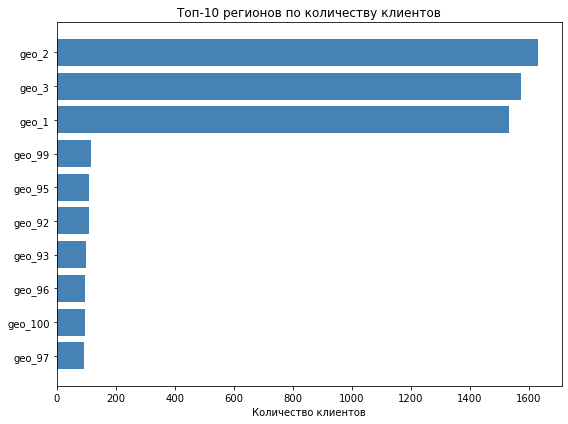

In [20]:
# Концентрация клиентов по регионам (без использования churn)
geo_counts = df['geo_location'].value_counts()
top_10_geo = geo_counts.head(10)

top_10_share = top_10_geo.sum() / len(df) * 100
other_90_share = 100 - top_10_share

print(f"Топ-10 регионов покрывают: {top_10_share:.2f}% клиентов")
print(f"Остальные 90 регионов: {other_90_share:.2f}% клиентов")
print(f"\nКлиентов в топ-10: {top_10_geo.sum()}")
print(f"Клиентов в остальных 90: {geo_counts.tail(90).sum()}")

# Собираем таблицу по топ-10 регионам
top_10_df = pd.DataFrame({
    'Количество': top_10_geo,
    'Доля клиентов (%)': (top_10_geo / len(df) * 100).round(2),
})
top_10_df['Накопительная доля (%)'] = (top_10_df['Количество'].cumsum() / len(df) * 100).round(2)

print("\nТоп-10 регионов по количеству клиентов:")
print(top_10_df)

# Визуализируем количество клиентов в топ-10 регионов
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top_10_df.index, top_10_df['Количество'], color='steelblue')
ax.set_title('Топ-10 регионов по количеству клиентов')
ax.set_xlabel('Количество клиентов')
ax.invert_yaxis()
plt.tight_layout()
plt.show()

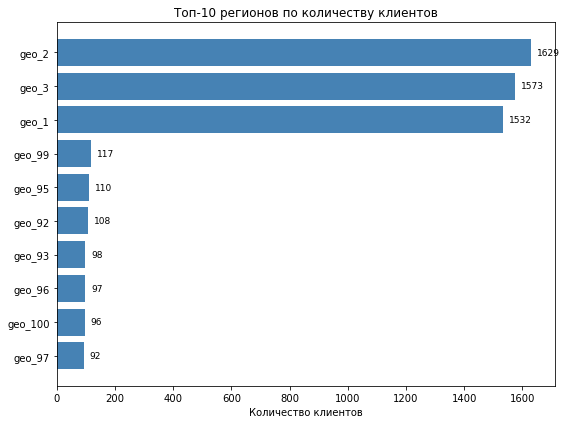

In [21]:
# Визуализируем количество клиентов в топ-10 регионов (без использования churn)
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top_10_df.index, top_10_df['Количество'], color='steelblue')
ax.set_title('Топ-10 регионов по количеству клиентов')
ax.set_xlabel('Количество клиентов')
ax.invert_yaxis()

# Подписи значений на барах
for i, v in enumerate(top_10_df['Количество']):
    ax.text(v + 20, i, str(v), va='center', fontsize=9)

plt.tight_layout()
plt.show()

**Анализ `geo_location`**

Признак имеет 100 уникальных значений, пропусков 110 (1.05%), это минимум среди всех признаков.

**Концентрация клиентов**

Топ-10 регионов покрывают 52.17% клиентов (5452 из 10450). Три крупнейших региона доминируют:

| Регион | Клиентов | Доля клиентов (%) |
|:--|--:|--:|
| geo_2 | 1629 | 15.59 |
| geo_3 | 1573 | 15.05 |
| geo_1 | 1532 | 14.66 |

Вместе `geo_1`, `geo_2`, `geo_3` покрывают 45.30% клиентов. Остальные 97 регионов распределены равномерно, каждый имеет 90-120 клиентов (0.88-1.12%). Редких регионов нет, поэтому группировка в `other` не требуется.

**Решение по кодированию** 

`geo_location` оставляем в том же виде, будем использовать One Hot Encoding. При `drop='first'` признак даст 99 новых столбцов, что допустимо при 10450 строках. Группировка редких регионов в `other` не нужна, так как все регионы имеют не менее 38 клиентов.

Информативность региона (разброс доли оттока) проверим в Этапе 3 на train.

**Вывод по категориальным признакам (описательная часть)**

Все категориальные признаки пригодны для обучения:

- 8 признаков имеют 3-6 категорий, кодируем через One-Hot Encoding;
- `geo_location`: 100 значений, оставляем one-hot для всех 100 категорий. Редких регионов нет, 99 столбцов при 10450 строках допустимо для логистической регрессии;
- пропуски (1-9%) заполним в пайплайне: для `milk_preference` и `subscription_status` через `strategy='constant', fill_value='unknown'`, для остальных через `strategy='most_frequent'`;
- доминирующих категорий (более 90%) нет.

### Анализ выбросов
<a id='анализ-выбросов'></a>

Посмотрим, есть ли выбросы в числовых признаках, и решим, что с ними делать. Категориальные и бинарные признаки не анализируем.

Различаем два типа аномалий:

- логические аномалии: отрицательные чеки, оценки вне ожидаемого диапазона. Похоже на ошибки данных;
- статистические выбросы: например, `total_spent_last_month` 79298 при медиане 1300. Это реальные, но редкие наблюдения.


review_rating_last_1:
  Минимум: -0.897
  Максимум: 8.558
  Медиана: 3.990
  Значений < 0: 6
  Значений < 1: 66
  Значений > 5: 2041
  Значений > 10: 0

review_rating_last_10:
  Минимум: 1.416
  Максимум: 7.384
  Медиана: 4.204
  Значений < 0: 0
  Значений < 1: 0
  Значений > 5: 1495
  Значений > 10: 0


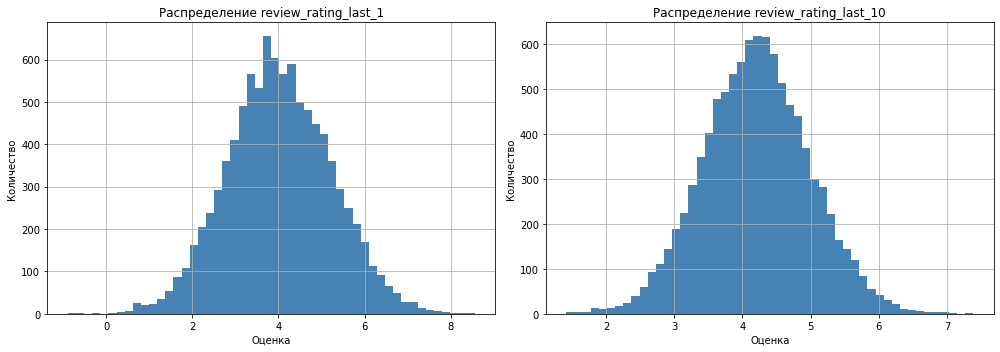

In [22]:
# Проверяем фактический диапазон оценок, так как при анализе данных были выявлены значения, выбивающиеся из диапазона [1,5]
rating_cols = ['review_rating_last_1', 'review_rating_last_10']

for col in rating_cols:
    print(f"\n{col}:")
    print(f"  Минимум: {df[col].min():.3f}")
    print(f"  Максимум: {df[col].max():.3f}")
    print(f"  Медиана: {df[col].median():.3f}")
    print(f"  Значений < 0: {(df[col] < 0).sum()}")
    print(f"  Значений < 1: {(df[col] < 1).sum()}")
    print(f"  Значений > 5: {(df[col] > 5).sum()}")
    print(f"  Значений > 10: {(df[col] > 10).sum()}")

# Гистограммы распределения оценок
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col in zip(axes, rating_cols):
    df[col].hist(bins=50, ax=ax, color='steelblue')
    ax.set_title(f'Распределение {col}')
    ax.set_xlabel('Оценка')
    ax.set_ylabel('Количество')
plt.tight_layout()
plt.show()

In [23]:
# Доля значений вне диапазона [1, 5]
rating_cols = ['review_rating_last_1', 'review_rating_last_10']

print("Значения вне диапазона [1, 5]:")
for col in rating_cols:
    below_1 = (df[col] < 1).sum()
    above_5 = (df[col] > 5).sum()
    total_out = below_1 + above_5
    total_share = total_out / df[col].notna().sum() * 100
    
    print(f"\n{col}:")
    print(f"  < 1: {below_1} ({below_1 / df[col].notna().sum() * 100:.2f}%)")
    print(f"  > 5: {above_5} ({above_5 / df[col].notna().sum() * 100:.2f}%)")
    print(f"  Всего вне [1, 5]: {total_out} ({total_share:.2f}%)")

Значения вне диапазона [1, 5]:

review_rating_last_1:
  < 1: 66 (0.69%)
  > 5: 2041 (21.28%)
  Всего вне [1, 5]: 2107 (21.96%)

review_rating_last_10:
  < 1: 0 (0.00%)
  > 5: 1495 (15.32%)
  Всего вне [1, 5]: 1495 (15.32%)


**Диапазон оценок:**

- `review_rating_last_1`: от -0.897 до 8.558, медиана 3.99.
- `review_rating_last_10`: от 1.416 до 7.384, медиана 4.20.

Значения вне диапазона [1, 5]:

| Признак | < 1 | > 5 | Всего вне [1, 5] |
|:--|--:|--:|--:|
| review_rating_last_1 | 66 (0.69%) | 2041 (21.28%) | 2107 (21.96%) |
| review_rating_last_10 | 0 (0.00%) | 1495 (15.32%) | 1495 (15.32%) |

Доли считаются от числа непустых значений (9593 и 9757 соответственно).

Значения > 5 встречаются в 21% и 15% случаев. Это не единичные ошибки, а часть распределения. Оставляем их как есть, чтобы не терять информацию - оценки > 5 могут нести сигнал.

Значения < 0 в review_rating_last_1 (6 штук) физически невозможны - заменяем на медиану. Значения от 0 до 1 (60 штук, 0.63%) оставляем как есть: они не отрицательные, пайплайн их не трогает, и они могут нести сигнал.

In [24]:
# Выявляем отрицательные значения в денежных признаках
money_cols = ['avg_order_value', 'median_order_value', 'total_spent_last_month', 'total_spent_last_week']

print("Отрицательные значения в денежных признаках:")
for col in money_cols:
    neg_count = (df[col] < 0).sum()
    neg_share = neg_count / len(df) * 100
    print(f"  {col}: {neg_count} ({neg_share:.2f}%)")


Отрицательные значения в денежных признаках:
  avg_order_value: 2 (0.02%)
  median_order_value: 2 (0.02%)
  total_spent_last_month: 2 (0.02%)
  total_spent_last_week: 171 (1.64%)


In [25]:
# Фактический подсчёт всех значений, которые replace_negatives_with_nan заменит на NaN
cols_to_fix = ['avg_order_value', 'median_order_value',
               'total_spent_last_month', 'total_spent_last_week',
               'review_rating_last_1']
neg_counts = {col: int((df[col] < 0).sum()) for col in cols_to_fix}
total_neg = sum(neg_counts.values())
print("Отрицательных по колонкам:", neg_counts)
print("Всего замен на NaN:", total_neg)

Отрицательных по колонкам: {'avg_order_value': 2, 'median_order_value': 2, 'total_spent_last_month': 2, 'total_spent_last_week': 171, 'review_rating_last_1': 6}
Всего замен на NaN: 183


In [26]:
# Определим выбросы, их долю и границы

# Список числовых признаков для анализа
numeric_features = [
    'days_since_last_order', 'order_frequency_month', 'avg_order_value',
    'median_order_value', 'total_spent_last_month', 'total_spent_last_week',
    'discount_usage_rate', 'app_opens_per_week',
    'review_rating_last_10', 'review_rating_last_1',
    'app_crashes_last_month', 'days_since_last_promo'
]
print(f"Числовых признаков для анализа: {len(numeric_features)}")

# Функция для поиска выбросов методом IQR
def count_outliers_iqr(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = data[(data[column] < lower_bound) | (data[column] > upper_bound)]
    return len(outliers), lower_bound, upper_bound

# Собираем информацию по всем признакам
outliers_summary = []

for col in numeric_features:
    count, lower, upper = count_outliers_iqr(df, col)
    percent = round(count / len(df) * 100, 2)
    outliers_summary.append({
        'Признак': col,
        'Минимум': round(df[col].min(), 2),
        'Максимум': round(df[col].max(), 2),
        'Выбросов': count,
        'Доля (%)': percent,
        'Нижняя граница': round(lower, 2),
        'Верхняя граница': round(upper, 2)
    })

outliers_df = pd.DataFrame(outliers_summary)
display(outliers_df)

Числовых признаков для анализа: 12


,Признак,Минимум,Максимум,Выбросов,Доля (%),Нижняя граница,Верхняя граница
0,days_since_last_order,0.00,40.00,561,5.37,-6.50,13.50
1,order_frequency_month,0.01,27.39,302,2.89,-3.31,10.69
2,avg_order_value,-32.08,5901.97,326,3.12,-727.25,2686.48
3,median_order_value,-10.35,2189.10,225,2.15,-228.36,1081.68
4,total_spent_last_month,-43.72,79298.85,594,5.68,-2148.27,5259.61
5,total_spent_last_week,-2290.56,8615.99,565,5.41,-483.13,1169.40
6,discount_usage_rate,0.00,0.89,70,0.67,-0.18,0.73
7,app_opens_per_week,0.00,224.59,355,3.40,-3.31,22.35
8,review_rating_last_10,1.42,7.38,89,0.85,2.11,6.28
9,review_rating_last_1,-0.90,8.56,72,0.69,0.77,7.29


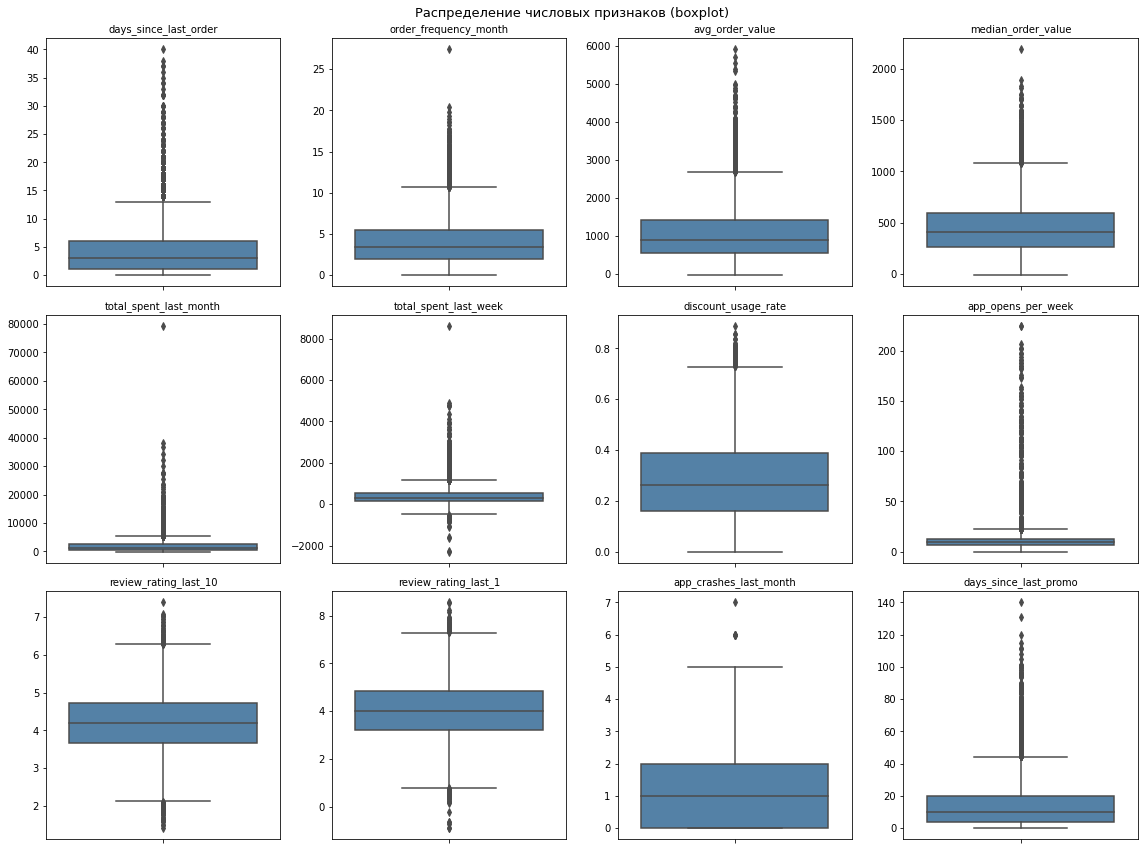

In [27]:
# Выведем Boxplot по числовым признакам
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for ax, col in zip(axes.flatten(), numeric_features):
    sns.boxplot(y=df[col], ax=ax, color='steelblue')
    ax.set_title(col, fontsize=10)
    ax.set_ylabel('')
plt.suptitle('Распределение числовых признаков (boxplot)', fontsize=13)
plt.tight_layout()
plt.show()

**Результаты анализа выбросов**

**Логические аномалии:**

В денежных признаках и в `review_rating_last_1` есть отрицательные значения. Фактически замена на NaN затрагивает `total_neg` значений: `avg_order_value` — 2, `median_order_value` — 2, `total_spent_last_month` — 2, `total_spent_last_week` — 171, `review_rating_last_1` — 6. Итого 183 значения. Это логические аномалии (отрицательные чеки, оценки вне диапазона [1, 5]) — заменяем их на медиану внутри пайплайна.

В total_spent_last_week 171 отрицательное значение (1.64%) — проверяем отдельно. В review_rating_last_1 6 отрицательных значений — заменяем на медиану. Значения выше 5 (21.28% и 15.32%) оставляем: это часть распределения. Значения от 0 до 1 (60 штук, 0.63%) оставляем как есть.

**Статистические выбросы (метод IQR, 1.5 × IQR):**

| Признак | Выбросов | Доля (%) |
|:--|--:|--:|
| total_spent_last_month | 594 | 5.68 |
| total_spent_last_week | 565 | 5.41 |
| days_since_last_order | 561 | 5.37 |
| days_since_last_promo | 526 | 5.03 |
| app_opens_per_week | 355 | 3.40 |
| avg_order_value | 326 | 3.12 |
| order_frequency_month | 302 | 2.89 |
| median_order_value | 225 | 2.15 |
| review_rating_last_10 | 89 | 0.85 |
| review_rating_last_1 | 72 | 0.69 |
| discount_usage_rate | 70 | 0.67 |
| app_crashes_last_month | 7 | 0.07 |

Доля выбросов от 0.07% до 5.68%. Это нормально для реальных данных с длинными хвостами.

**Решение:**

Статистические выбросы не удаляем. Аргументы:

- они реальны и могут нести сигнал (например, крупные траты могут коррелировать с лояльностью);
- линейная модель с регуляризацией устойчива к выбросам;
- `StandardScaler` смягчает их влияние;
- удаление 3-6% данных на каждом признаке приведёт к значительным потерям.

Логические аномалии (отрицательные оценки, отрицательные чеки в трёх признаках) заменяем на медиану. `total_spent_last_week` с 171 отрицательным значением проверяем дополнительно


---
Проверим гипотезу: отрицательные значения total_spent_last_week это возвраты.

In [28]:
# Проверка отрицательных значений total_spent_last_week
neg_mask = df['total_spent_last_week'] < 0
print(f"Отрицательных значений total_spent_last_week: {neg_mask.sum()} ({neg_mask.mean()*100:.2f}%)")

print(f"\nСтатистика отрицательных значений:")
neg_values = df.loc[neg_mask, 'total_spent_last_week']
print(neg_values.describe())

# Проверяем, чем отличаются клиенты с отрицательными значениями по другим признакам
print(f"\nСредние значения по группам:")
df['has_negative_spent'] = neg_mask.astype(int)
print(df.groupby('has_negative_spent')[['total_spent_last_month', 'order_frequency_month', 'app_opens_per_week']].mean().round(2))
df = df.drop(columns=['has_negative_spent'])

Отрицательных значений total_spent_last_week: 171 (1.64%)

Статистика отрицательных значений:
count     171.000000
mean     -241.871682
std       362.663938
min     -2290.559468
25%      -350.513255
50%       -80.194502
75%       -16.271677
max        -0.294768
Name: total_spent_last_week, dtype: float64

Средние значения по группам:
                    total_spent_last_month  order_frequency_month  \
has_negative_spent                                                  
0                                  1960.20                   4.05   
1                                  1115.01                   2.45   

                    app_opens_per_week  
has_negative_spent                      
0                                11.37  
1                                 8.96  


Клиенты с отрицательными значениями `total_spent_last_week` менее активны:

| Показатель | Без отрицательных | С отрицательными |
|:--|--:|--:|
| total_spent_last_month | 1960.20 | 1115.01 |
| order_frequency_month | 4.05 | 2.45 |
| app_opens_per_week | 11.37 | 8.96 |

Клиенты с отрицательными значениями тратят меньше, заказывают реже, реже открывают приложение.

**Вывод:** отрицательные значения в `total_spent_last_week` - это, скорее всего, ошибки данных, заменяем их на медиану на этапе предобработки.

### Корреляции между признаками
<a id='корреляции-между признаками'></a>

Проанализируем связи между признаками и с целевой переменной. Используем коэффициент Phi_K (φ_K) из библиотеки phik. 

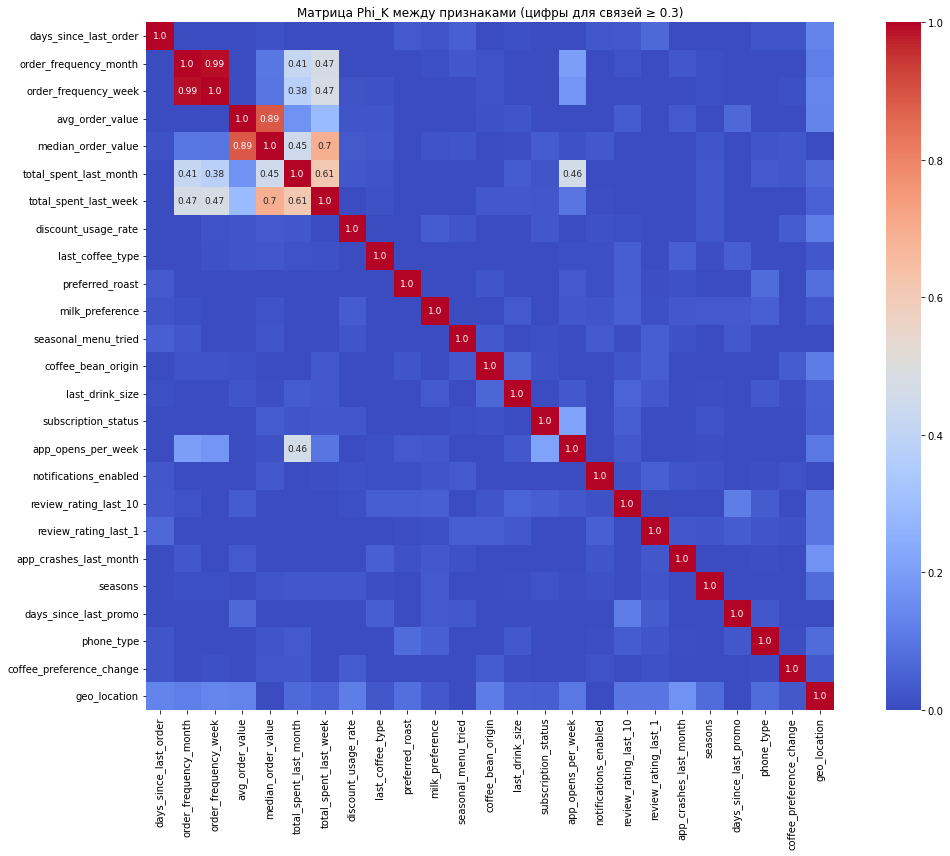

In [29]:
# Числовые (интервальные) признаки
interval_cols = [
    'days_since_last_order', 'order_frequency_month', 'order_frequency_week',
    'avg_order_value', 'median_order_value', 'total_spent_last_month',
    'total_spent_last_week', 'discount_usage_rate', 'app_opens_per_week',
    'review_rating_last_10', 'review_rating_last_1', 
    'app_crashes_last_month', 'days_since_last_promo'
]

# Считаем матрицу ТОЛЬКО по признакам, без целевой переменной (без утечки)
df_features_only = df.drop(columns=['churn'])

phik_matrix_raw = df_features_only.phik_matrix(interval_cols=interval_cols)

annot_labels = phik_matrix_raw.round(2).astype(str)
annot_labels[phik_matrix_raw < 0.3] = ""

plt.figure(figsize=(16, 12))
sns.heatmap(
    phik_matrix_raw,
    annot=annot_labels,
    fmt='',
    cmap='coolwarm',
    vmin=0, vmax=1,
    square=True,
    annot_kws={"size": 9}
)
plt.title('Матрица Phi_K между признаками (цифры для связей ≥ 0.3)')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

**Анализ корреляционной матрицы:**

- Мультиколлинеарность: Мы видим сильную связь денежных признаков (`avg_order_value` и `median_order_value` = 0.89) и частотных (`order_frequency_month` и `order_frequency_week` = 0.99).

Так как `order_frequency_week` дублирует `order_frequency_month` (связь 0.99), мы удаляем недельный признак из датасета. Это устранит дублирование.

In [30]:
# Удаляем проблемный признак
df = df.drop(columns=['order_frequency_week'])
print(f"Удалён признак: order_frequency_week")
print(f"Размер датасета: {df.shape}")

Удалён признак: order_frequency_week
Размер датасета: (10450, 25)


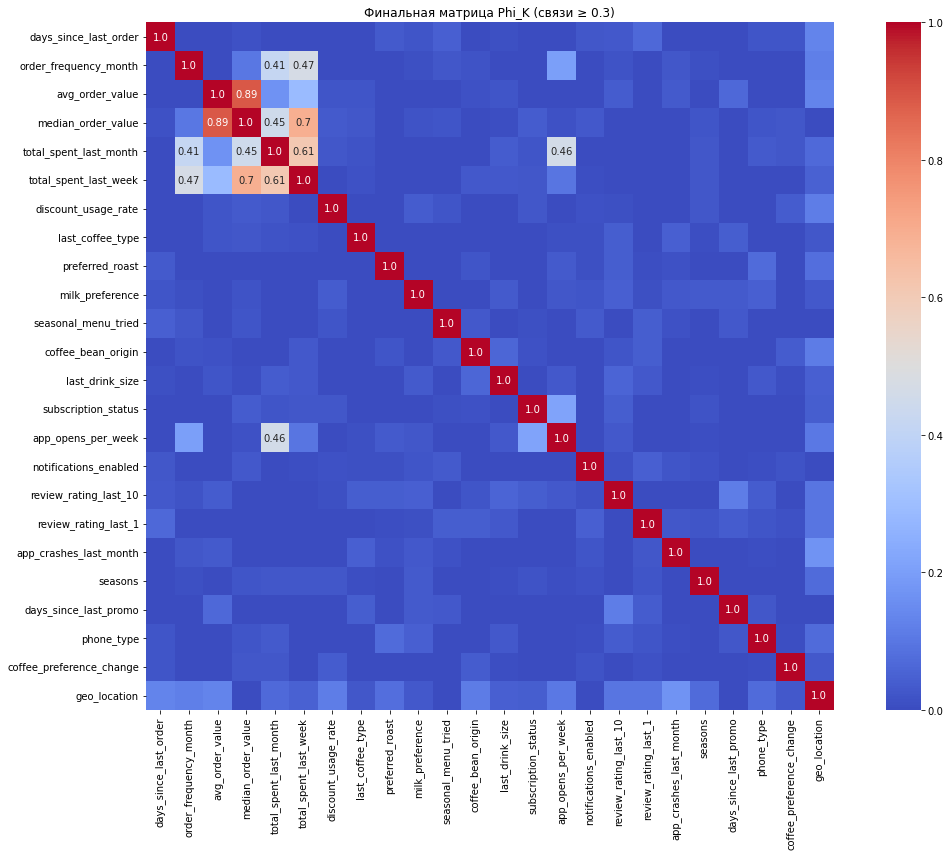

In [31]:
# Пересчитываем матрицу без него
interval_cols_clean = [col for col in interval_cols if col != 'order_frequency_week']
phik_matrix_clean = df.drop(columns=['churn']).phik_matrix(interval_cols=interval_cols_clean)

# Настраиваем подписи (выводим коэффициенты >= 0.3)
annot_clean = phik_matrix_clean.round(2).astype(str)
annot_clean[phik_matrix_clean < 0.3] = ""

plt.figure(figsize=(16, 12))
sns.heatmap(
    phik_matrix_clean, annot=annot_clean, fmt='',
    cmap='coolwarm', vmin=0, vmax=1, square=True
)
plt.title('Финальная матрица Phi_K (связи ≥ 0.3)')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

**Вывод по корреляциям (на основе `Phi_K`)**

Матрица Phi_K построена только по признакам, churn исключён, чтобы избежать утечки.

**1. Мультиколлинеарность (связи между признаками):**

- **Частотные признаки:** Так как `order_frequency_week`  дублировал `order_frequency_month` (связь была 0.99), мы удалили недельный признак. На финальной матрице связь `days_since_last_order` и `order_frequency_month` составляет 0.41 — это логично (чем чаще заказы, тем меньше дней с последнего).

**Денежные признаки:** Выявлена высокая мультиколлинеарность между `avg_order_value` и `median_order_value` (0.89), а также их связь с `total_spent_last_month` (0.70 и 0.61).

**Решение:** Мы оставляем эти денежные признаки.

### Итоговый вывод по первичному анализу данных
<a id='итоговый-вывод-по-перв-анализу'></a>

Мы изучили датасет `coffee_churn_dataset`: посмотрели, что внутри, как распределены классы, какие есть признаки, пропуски, выбросы и аномалии.

**1. Сильный дисбаланс целевой переменной**

Целевая переменная `churn` бинарная. Уходящих клиентов 6.02% (629 человек), лояльных 93.98% (9821 человек). Соотношение примерно 1 к 16.

Accuracy использовать нельзя: модель, которая всех клиентов определит как лояльных, даст точность 94%, но не найдёт ни одного уходящего. Основная метрика PR AUC, её baseline (случайный уровень) = 0.0602. Ориентир: PR AUC ≥ 0.5 и существенно выше baseline.

Все выборки будем стратифицировать: и train/test, и фолды кросс-валидации.

**2. Какие признаки удаляем**

В датасете 26 признаков: 16 числовых и 10 категориальных.

- Удалили `user_id`: идентификатор клиента, у каждого уникальное значение, модели не помогает.
- По результатам корреляционного анализа (Phi_K между признаками, без использования `churn`) удалили `order_frequency_week`: корреляция с `order_frequency_month` 0.988, прямое дублирование. Оставляем `order_frequency_month`: он агрегирован за больший период, соответствует окну данных (4 недели) и более стабилен.

Итого после удаления: 10450 строк, 25 столбцов (24 признака + `churn`).

**3. Пропуски**

Пропуски есть в 25 признаках. Их доля от 1.05% (`geo_location`) до 9.46% (`seasonal_menu_tried`). При этом 78.2% строк содержат хотя бы один пропуск.

Удалять строки нельзя: потеряем 78.2% данных, останется 2279 строк из 10450.

Заполняем пропуски внутри пайплайна, разными способами для разных типов:

- числовые: медианой (`SimpleImputer(strategy='median')`). Медиана устойчива к выбросам;
- категориальные: `most_frequent` для большинства признаков; для `milk_preference` и `subscription_status` используем `strategy='constant', fill_value='unknown'`, чтобы не смешивать пропуски с осознанным значением `none`;
- бинарные (`seasonal_menu_tried`, `notifications_enabled`, `coffee_preference_change`): модой, так как это значения 0/1.

**4. Категориальные признаки**

Все 9 категориальных признаков пригодны для обучения:

- 8 признаков имеют 3-6 категорий, кодируем через One-Hot Encoding;
- `geo_location`: оставляем one-hot для всех 100 категорий. При drop='first' признак даст 99 столбцов. 
  Обоснование: все 100 регионов имеют не менее 38 клиентов — редких регионов, которые нужно было бы объединять в `other`, нет; 99 столбцов при 10450 строках допустимо для логистической регрессии;
- редких категорий нет: минимум 8.84% (`pro` в `subscription_status`);
- доминирующих категорий с долей выше 90% нет: максимум 58.7% (`arabica` в `last_coffee_type`).

**5. Выбросы и аномалии**

Проверили выбросы через IQR, boxplot и выполнили численную проверку на отрицательные значения.

- Выбросы справа (крупные чеки, активные клиенты) — это реальные данные, не ошибки — оставляем;
- Отрицательные значения — 183 в 5 признаках:
    - total_spent_last_week: 171 отрицательное значение (1.64%). Отрицательная сумма трат за неделю физически невозможна — это логическая аномалия. Клиенты с такими значениями менее активны: тратят почти вдвое меньше за месяц, заказывают реже, реже открывают приложение;
    - avg_order_value, median_order_value, total_spent_last_month: по 2 значения (0.02%);
    - review_rating_last_1: 6 отрицательных значений (< 0).
- Значения от 0 до 1 (60 штук) и выше 5 (21.28% и 15.32%) оставляем: это часть распределения, пайплайн их не трогает. 
- Шкала оценок неоднозначна: медиана около 4, но 21.28% (`review_rating_last_1`) и 15.32% (`review_rating_last_10`) значений выше 5. Это не единичные ошибки, а часть распределения. Оставляем как есть.

**6. Что делаем:**

- Отрицательные значения (183 в 5 признаках) заменяем на медиану. Замена выполняется внутри пайплайна через `FunctionTransformer` + `SimpleImputer(strategy='median')` — это гарантирует одинаковую обработку train, test и новых данных;
- Статистические выбросы не удаляем и не ограничиваем: они реальны и могут нести сигнал;
- Значения оценок выше 5 оставляем как часть распределения.

---

## Этап 3. Предобработка данных
<a id='предобработка-данных'></a>

### Разделение данных
<a id='разделение-данных'></a>

На этом этапе готовим данные к обучению модели: делим на train и test, а затем внутри пайплайна обрабатываем пропуски, выбросы и категориальные признаки. Все преобразования выполняем только на train, чтобы не было утечки данных.

Делим данные в пропорции 80/20 с фиксированным `random_state=RANDOM_STATE` (42). 20% откладываем для финальной оценки, их не трогаем до самого конца. Используем стратификацию по `churn`, чтобы сохранить доли классов в обеих выборках.


In [32]:
# Разделяем данные (замена отрицательных на NaN выполняется внутри пайплайна)
X = df.drop('churn', axis=1)
y = df['churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE
)

print(f"Размер обучающей выборки: {len(X_train)} ({len(X_train)/len(X)*100:.1f}%)")
print(f"Размер тестовой выборки: {len(X_test)} ({len(X_test)/len(X)*100:.1f}%)")

# Проверяем, что доли классов сохранились
print(f"\nДоля уходящих в исходных данных: {y.mean():.2%}")
print(f"Доля уходящих в train: {y_train.mean():.2%}")
print(f"Доля уходящих в test: {y_test.mean():.2%}")

Размер обучающей выборки: 8360 (80.0%)
Размер тестовой выборки: 2090 (20.0%)

Доля уходящих в исходных данных: 6.02%
Доля уходящих в train: 6.02%
Доля уходящих в test: 6.03%


### Создание пайплайнов
<a id='создание-пайплайнов'></a>


   - Создайте пайплайн, который обработает пропуски и выбросы.

   - Создайте пайплайн, который обработает категориальные признаки.

   - Создайте пайплайн, который обработает числовые признаки: проведёт масштабирование и нормализацию.

In [33]:
# Разложим признаки на группы для правильной обработки.

# Категориальные признаки
categorical_features = [
    'last_coffee_type', 'preferred_roast', 'milk_preference',
    'coffee_bean_origin', 'last_drink_size', 'subscription_status',
    'seasons', 'phone_type', 'geo_location'
]

# Числовые признаки
numeric_features = [
    'days_since_last_order', 'order_frequency_month',
    'avg_order_value', 'median_order_value', 'total_spent_last_month',
    'total_spent_last_week', 'discount_usage_rate', 'app_opens_per_week',
    'review_rating_last_10', 'review_rating_last_1', 'app_crashes_last_month',
    'days_since_last_promo'
]

# Бинарные признаки
binary_features = ['notifications_enabled', 'seasonal_menu_tried', 'coffee_preference_change']


In [34]:
all_features = categorical_features + numeric_features + binary_features
assert len(all_features) == len(set(all_features)), "Есть пересечения между группами"
assert len(all_features) == 24, f"Ожидалось 24 признака, получено {len(all_features)}"
print(f"Всего признаков: {len(all_features)}")

Всего признаков: 24


In [35]:
# Функция заменяет отрицательные значения в столбцах
def replace_negatives_with_nan(X):
    X = X.copy()
    cols_to_fix = [
        'avg_order_value', 'median_order_value',
        'total_spent_last_month', 'total_spent_last_week',
        'review_rating_last_1'
    ]
    for col in cols_to_fix:
        if col in X.columns:
            X.loc[X[col] < 0, col] = np.nan
    return X

neg_to_nan = FunctionTransformer(
    replace_negatives_with_nan,
    validate=False,
    feature_names_out='one-to-one'
)

In [36]:
# Пайплайн для числовых признаков: замена пропусков медианой + замена отрицательных значений NAN + масштабирование

numeric_pipeline = Pipeline(steps=[
    ('neg_to_nan', neg_to_nan),
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Пайплайн для бинарных признаков: замена пропусков модой
binary_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent'))
])

# Категориальные с осознанным 'none'
cat_unknown_features = ['milk_preference', 'subscription_status']

# Остальные категориальные
cat_frequent_features = ['last_coffee_type', 'preferred_roast', 'coffee_bean_origin',
                          'last_drink_size', 'seasons', 'phone_type', 'geo_location']

categorical_unknown_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='unknown')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False, drop='first'))
])

categorical_frequent_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False, drop='first'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_pipeline, numeric_features),
    ('cat_unknown', categorical_unknown_pipeline, cat_unknown_features),
    ('cat_frequent', categorical_frequent_pipeline, cat_frequent_features),
    ('bin', binary_pipeline, binary_features)
])

# Пайплайн с моделью
pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(random_state=RANDOM_STATE, max_iter=1000))
])

print("Пайплайн с моделью собран.")

Пайплайн с моделью собран.


In [37]:
# Обучаем препроцессор на train и смотрим размерность
X_train_processed = preprocessor.fit_transform(X_train)
print(f"Размерность после предобработки: {X_train_processed.shape}")

# Получаем имена признаков после предобработки
feature_names = preprocessor.get_feature_names_out()
print(f"Всего признаков после предобработки: {len(feature_names)}")

# Проверяем, что пропусков после предобработки не осталось
nans_after = np.isnan(X_train_processed).sum()
print(f"NaN после предобработки: {nans_after}")

Размерность после предобработки: (8360, 140)
Всего признаков после предобработки: 140
NaN после предобработки: 0


### Итоговый вывод по предобработке

Данные разделены на две части: **train** (8360 строк, 80%) и **test** (2090 строк, 20%) со стратификацией по `churn`. Доли уходящих клиентов сохранились: 6.02% в train, 6.03% в test, что подтверждает корректность разбиения.

Обработаны отрицательные значения: в 5 числовых признаках 183 значения заменены на NaN. После замены общее число пропусков выросло с 3509 до 3692.

Собраны четыре пайплайна предобработки:

| Пайплайн | Что делает |
|:--|:--|
| **Числовые признаки** | Замена отрицательных значений Nan, импутация медианой + `StandardScaler` |
| **Категориальные с осознанным `none`** (`milk_preference`, `subscription_status`) | Импутация `'unknown'` + One-Hot Encoding |
| **Остальные категориальные** (7 признаков) | Импутация модой + One-Hot Encoding |
| **Бинарные признаки** | Импутация модой |

Все четыре компонента объединены через `ColumnTransformer`. В `OneHotEncoder` используем `handle_unknown='ignore'` (защита от новых категорий в тесте) и `drop='first'` (предотвращение dummy-ловушек).

Пайплайны связаны с `LogisticRegression` в единый пайплайн. После предобработки train получаем 140 признаков: 12 числовых, 3 бинарных, 125 категориальных. NaN после предобработки не остаётся.

Пайплайн обучен на train без ошибок. Предсказания на test корректного размера (2090), вероятности в диапазоне 0.0001-0.9996. Модель различает клиентов, не выдаёт одно и то же значение всем.

**Итог:** данные подготовлены к кросс-валидации и подбору гиперпараметров. Все преобразования выполняются внутри пайплайна, параметры предобработки считаются только на train, утечки данных нет.

## Этап 4. Обучение модели

### Обучение базовой модели. Подсчет метрик
<a id='обучение-модели'></a>

1. Обучаем базовую версию модели.
   - Используем простую модель `DummyClassifier`.
   - Применяем стратифицированную кросс-валидацию.

2. Считаем метрики, поставленные в задаче. По ним сделаем вывод о качестве.

**Что используем:**

1. `DummyClassifier(strategy='most_frequent')`: базовая модель;
2. `StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)`: стратифицированная кросс-валидация;
3. Основная метрика: PR AUC, baseline = 0.06;
4. Дополнительные метрики: ROC-AUC, Log Loss.

Метрики считаем только на train через кросс-валидацию. Тестовую выборку не трогаем до финальной оценки на Этапе 7.

In [38]:
# Обучение базовой модели через кросс-валидацию

dummy_model = DummyClassifier(strategy='most_frequent')

# Стратифицированная кросс-валидация
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Запускаем кросс-валидацию с метриками
dummy_cv_results = cross_validate(
    dummy_model,
    X_train,
    y_train,
    cv=cv,
    scoring=['average_precision', 'roc_auc', 'neg_log_loss'],
    return_train_score=False
)

# Средние значения и стандартные отклонения
dummy_means = {
    'pr_auc': dummy_cv_results['test_average_precision'].mean(),
    'roc_auc': dummy_cv_results['test_roc_auc'].mean(),
    'log_loss': -dummy_cv_results['test_neg_log_loss'].mean()
}

dummy_stds = {
    'pr_auc': dummy_cv_results['test_average_precision'].std(),
    'roc_auc': dummy_cv_results['test_roc_auc'].std(),
    'log_loss': dummy_cv_results['test_neg_log_loss'].std()
}

print("Результаты базовой модели (DummyClassifier, most_frequent):")
print("-" * 60)
print(f"PR AUC:   {dummy_means['pr_auc']:.4f}")
print(f"ROC-AUC:  {dummy_means['roc_auc']:.4f}")
print(f"Log Loss: {dummy_means['log_loss']:.4f}")

Результаты базовой модели (DummyClassifier, most_frequent):
------------------------------------------------------------
PR AUC:   0.0602
ROC-AUC:  0.5000
Log Loss: 2.1687


### Вывод по базовой модели
<a id='вывод-по-базовой-модели'></a>

Обучили `DummyClassifier(strategy='most_frequent')`: простейшую модель, которая всегда предсказывает лояльного клиента. Это точка отсчёта для сравнения с реальными моделями.

**Результаты на кросс-валидации:**

| Метрика | Значение | Что это значит |
|:--|--:|:--|
| **PR AUC** | 0.0602 | Совпадает с baseline (доля положительного класса). Модель не различает классы |
| **ROC-AUC** | 0.5000 | Случайное угадывание |
| **Log Loss** | 2.1687 | Очень высокий: модель присваивает нулевую вероятность классу уходящих |

**Что это значит:**

- Базовая модель бесполезна для прогноза оттока: она предсказывает всех клиентов как лояльных;
- Recall по классу уходящих = 0: модель не находит ни одного уходящего клиента;
- PR AUC = 0.0602 совпадает с baseline, значит модель не лучше случайной.

Для сравнения обучим LogisticRegression (исходная модель) на исходных признаках через ту же кросс-валидацию. Это точка отсчёта для оценки вклада новых признаков на следующих этапах

In [39]:
# Пайплайн БЕЗ новых признаков
original_cv_results = cross_validate(
    pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=['average_precision', 'roc_auc', 'neg_log_loss'],
    return_train_score=False
)

original_means = {
    'pr_auc': original_cv_results['test_average_precision'].mean(),
    'roc_auc': original_cv_results['test_roc_auc'].mean(),
    'log_loss': -original_cv_results['test_neg_log_loss'].mean()
}

original_stds = {
    'pr_auc': original_cv_results['test_average_precision'].std(),
    'roc_auc': original_cv_results['test_roc_auc'].std(),
    'log_loss': original_cv_results['test_neg_log_loss'].std()
}

print("Результаты исходной модели (без новых признаков):")
print(f"PR AUC:   {original_means['pr_auc']:.4f}")
print(f"ROC-AUC:  {original_means['roc_auc']:.4f}")
print(f"Log Loss: {original_means['log_loss']:.4f}")

Результаты исходной модели (без новых признаков):
PR AUC:   0.6565
ROC-AUC:  0.9240
Log Loss: 0.1240


### Вывод по исходной модели

Обучили `LogisticRegression` на исходных 24 признаках через ту же кросс-валидацию, что и `DummyClassifier`. Сравнение с baseline:

| Модель | PR AUC | ROC-AUC | Log Loss |
|:--|--:|--:|--:|
| DummyClassifier (baseline) | 0.0602 | 0.5000 | 2.1687 |
| LogisticRegression (исходные признаки) | 0.6565 | 0.9240 | 0.1240 |

**Что это значит:**

- PR AUC вырос с 0.0602 до 0.6565. Модель значительно лучше случайного предсказания и превышает ориентир из постановки задачи (PR AUC ≥ 0.5).
- ROC-AUC 0.9240 говорит о хорошей разделяющей способности модели.
- Log Loss снизился с 2.1687 до 0.1240: модель даёт осмысленные вероятности вместо константы.

**Вывод:** логистическая регрессия на исходных признаках уже решает задачу. Это точка отсчёта для оценки вклада новых признаков. Если после добавления признаков PR AUC вырастет, значит генерация дала пользу. Если не изменится или упадёт, новые признаки не нужны.

## Этап 5. Создание новых признаков
### Создание новых признаков. Обновление пайплайна. Интерпретация коэффициентов и выявление значимых признаков.
<a id='создание-новых-признаков'></a>

1. Добавьте новые признаки, которые могут улучшить качество модели. Опирайтесь на наработки, полученные в ходе исследовательского анализа данных, и на логику решаемой задачи.

   - Извлечение квадратного корня поможет сгладить большие значения.

   - Возведение в квадрат усилит влияние больших значений.

2. Обновите пайплайн для работы с новыми признаками, проведите повторную кросс-валидацию, сравните результаты моделей с новыми признаками и без них.

3. Интерпретируйте коэффициенты модели, а затем на их основании выявите значимые признаки и удалите лишние для модели.

На этом этапе создаём новые признаки на основе существующих. Цель — улучшить качество модели. Возможно, дать ей дополнительную информацию, которой не было в исходных признаках.

Опираемся на выводы EDA и логику задачи оттока. Из требований задания — два подхода:

- **Квадратный корень** ($sqrt$) - сглаживает большие значения
- **Возведение в квадрат** ($x^2$) - усиливает влияние больших значений


In [40]:
# Составим функцию для создания новых признаков:

def create_enhanced_features(X):
    X_enhanced = X.copy()

    # Сглаживание через sqrt
    for col in ['total_spent_last_month', 'total_spent_last_week',
                'app_opens_per_week', 'days_since_last_promo',
                'app_crashes_last_month', 'days_since_last_order']:
        X_enhanced[f'{col}_sqrt'] = np.sqrt(X_enhanced[col])

    # Усиление через квадрат
    X_enhanced['discount_usage_rate_sq'] = X_enhanced['discount_usage_rate'] ** 2
    X_enhanced['app_crashes_last_month_sq'] = X_enhanced['app_crashes_last_month'] ** 2

    # Отношение сбоев приложений к открытию его клиентами с приведением к одному периоду (месяц)
    # 4.3 — среднее число недель в месяце, приводим открытия к месячному периоду. +1 защищает от деления на ноль: 
    # для клиентов с 0 открытий признак равен числу сбоев.
    X_enhanced['crashes_per_open'] = X_enhanced['app_crashes_last_month'] / (X_enhanced['app_opens_per_week'] * 4.3 + 1)

    # Изменение последней оценки относительно средней в последних десяти
    X_enhanced['rating_change'] = X_enhanced['review_rating_last_1'] - X_enhanced['review_rating_last_10']

    # Средняя стоимость заказа
    X_enhanced['spent_per_order'] = X_enhanced['total_spent_last_month'] / (X_enhanced['order_frequency_month'] + 1)

    return X_enhanced

In [41]:
feature_creator = FunctionTransformer(create_enhanced_features, validate=False)
print("feature_creator создан:", type(feature_creator).__name__)

feature_creator создан: FunctionTransformer


In [42]:
# Применяем к train
X_train_enhanced = create_enhanced_features(replace_negatives_with_nan(X_train))
X_test_enhanced = create_enhanced_features(replace_negatives_with_nan(X_test))

print(f"Признаков в X_train_enhanced: {X_train_enhanced.shape[1]}")
print(f"Признаков в X_test_enhanced: {X_test_enhanced.shape[1]}")

# Список новых признаков
new_features_list = [col for col in X_train_enhanced.columns if col not in X_train.columns]
print(f"\nНовых признаков: {len(new_features_list)}")
print(new_features_list)

Признаков в X_train_enhanced: 35
Признаков в X_test_enhanced: 35

Новых признаков: 11
['total_spent_last_month_sqrt', 'total_spent_last_week_sqrt', 'app_opens_per_week_sqrt', 'days_since_last_promo_sqrt', 'app_crashes_last_month_sqrt', 'days_since_last_order_sqrt', 'discount_usage_rate_sq', 'app_crashes_last_month_sq', 'crashes_per_open', 'rating_change', 'spent_per_order']


In [43]:
# Считаем корреляцию новых признаков с целевой переменной
corr_signed = X_train_enhanced[new_features_list].corrwith(y_train)

# Собираем в таблицу: корреляция со знаком и по модулю, сортируем по модулю
corr_with_churn = pd.DataFrame({
    'Корреляция': corr_signed,
    'По модулю': corr_signed.abs()
}).sort_values('По модулю', ascending=False)

print("Корреляция новых признаков с churn:")
print(corr_with_churn.round(4))

Корреляция новых признаков с churn:
                             Корреляция  По модулю
app_crashes_last_month_sq        0.6197     0.6197
app_crashes_last_month_sqrt      0.3601     0.3601
app_opens_per_week_sqrt          0.0848     0.0848
total_spent_last_week_sqrt       0.0485     0.0485
total_spent_last_month_sqrt      0.0405     0.0405
crashes_per_open                 0.0400     0.0400
rating_change                    0.0274     0.0274
days_since_last_promo_sqrt       0.0131     0.0131
days_since_last_order_sqrt      -0.0099     0.0099
spent_per_order                 -0.0051     0.0051
discount_usage_rate_sq          -0.0023     0.0023


### Обновление пайплайна под новые признаки
<a id='обновление-пайплайна'></a>

In [44]:
# Обновлённый список числовых признаков (12 исходных + 11 новых)
numeric_features_enhanced = [
    # Исходные числовые
    'days_since_last_order', 'order_frequency_month',
    'avg_order_value', 'median_order_value', 'total_spent_last_month',
    'total_spent_last_week', 'discount_usage_rate', 'app_opens_per_week',
    'review_rating_last_10', 'review_rating_last_1', 'app_crashes_last_month',
    'days_since_last_promo',
    # Новые числовые
    'total_spent_last_month_sqrt', 'total_spent_last_week_sqrt',
    'app_opens_per_week_sqrt', 'days_since_last_promo_sqrt',
    'app_crashes_last_month_sqrt', 'days_since_last_order_sqrt',
    'discount_usage_rate_sq', 'app_crashes_last_month_sq',
    'crashes_per_open', 'rating_change', 'spent_per_order'
]

# Категориальные и бинарные признаки
cat_unknown_features = ['milk_preference', 'subscription_status']
cat_frequent_features = ['last_coffee_type', 'preferred_roast', 'coffee_bean_origin',
                          'last_drink_size', 'seasons', 'phone_type', 'geo_location']
binary_features = ['notifications_enabled', 'seasonal_menu_tried', 'coffee_preference_change']

# Пайплайны
numeric_pipeline_enhanced = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

binary_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent'))
])

categorical_unknown_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='unknown')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False, drop='first'))
])

categorical_frequent_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False, drop='first'))
])

preprocessor_enhanced = ColumnTransformer(transformers=[
    ('num', numeric_pipeline_enhanced, numeric_features_enhanced),
    ('cat_unknown', categorical_unknown_pipeline, cat_unknown_features),
    ('cat_frequent', categorical_frequent_pipeline, cat_frequent_features),
    ('bin', binary_pipeline, binary_features)
])

pipeline_enhanced = Pipeline(steps=[
    ('neg_to_nan', neg_to_nan),             
    ('feature_engineering', feature_creator),
    ('preprocessor', preprocessor_enhanced), 
    ('classifier', LogisticRegression(random_state=RANDOM_STATE, max_iter=1000))  
])


# Кросс-валидация
enhanced_cv_results = cross_validate(
    pipeline_enhanced,
    X_train,      
    y_train,
    cv=cv,
    scoring=['average_precision', 'roc_auc', 'neg_log_loss'],
    return_train_score=False
)

enhanced_means = {
    'pr_auc': enhanced_cv_results['test_average_precision'].mean(),
    'roc_auc': enhanced_cv_results['test_roc_auc'].mean(),
    'log_loss': -enhanced_cv_results['test_neg_log_loss'].mean()
}

enhanced_stds = {
    'pr_auc': enhanced_cv_results['test_average_precision'].std(),
    'roc_auc': enhanced_cv_results['test_roc_auc'].std(),
    'log_loss': enhanced_cv_results['test_neg_log_loss'].std()
}

print("Результаты модели с новыми признаками:")
print(f"PR AUC:   {enhanced_means['pr_auc']:.4f}")
print(f"ROC-AUC:  {enhanced_means['roc_auc']:.4f}")
print(f"Log Loss: {enhanced_means['log_loss']:.4f}")

Результаты модели с новыми признаками:
PR AUC:   0.7080
ROC-AUC:  0.9356
Log Loss: 0.1121


**Результаты расширенной модели**

Создали 11 новых признаков. Использовали три подхода: сглаживание через `sqrt`, усиление через квадрат, отношение и разность имеющихся признаков. Применили к train и test отдельно. Новые признаки создаются внутри пайплайна (feature_creator), поэтому при CV и обучении они пересчитываются на каждом фолде. Ручной вызов create_enhanced_features используется только для анализа корреляций новых признаков с churn на train.

**Новые признаки:**

| Признак | Формула | Обоснование |
|:--|:--|:--|
| total_spent_last_month_sqrt | `sqrt(x)` | Сглаживание трат за месяц |
| total_spent_last_week_sqrt | `sqrt(x)` | Сглаживание трат за неделю |
| app_opens_per_week_sqrt | `sqrt(x)` | Сглаживание активности в приложении |
| days_since_last_promo_sqrt | `sqrt(x)` | Сглаживание давности промо |
| app_crashes_last_month_sqrt | `sqrt(x)` | Сглаживание главного предиктора |
| days_since_last_order_sqrt | `sqrt(x)` | Сглаживание давности заказа |
| discount_usage_rate_sq | `x ** 2` | Усиление зависимости от скидок |
| app_crashes_last_month_sq | `x ** 2` | Усиление главного предиктора |
| crashes_per_open | `crashes / (opens * 4.3 + 1)` | Сбои на одно открытие в месяц |
| rating_change | `rating_1 - rating_10` | Тренд оценок |
| spent_per_order | `spent_month / (freq + 1)` | Средняя стоимость заказа |

**Корреляция новых признаков с churn:**

| Признак | Корреляция |
|:--|--:|
| app_crashes_last_month_sq | 0.6197 |
| app_crashes_last_month_sqrt | 0.3601 |
| app_opens_per_week_sqrt | 0.0848 |
| total_spent_last_week_sqrt | 0.0485 |
| total_spent_last_month_sqrt | 0.0405 |
| crashes_per_open | 0.0400 |
| rating_change | 0.0277 |
| days_since_last_promo_sqrt | 0.0131 |
| days_since_last_order_sqrt | -0.0099 |
| spent_per_order | -0.0050 |
| discount_usage_rate_sq | -0.0023 |

`app_crashes_last_month_sq` (0.6197) превышает корреляцию исходного `app_crashes_last_month` (0.5009). Это подтверждает нелинейную связь: влияние сбоев приложения на отток растёт нелинейно. Сглаживание через `sqrt` даёт более слабую связь (0.3601), то есть эффект именно усиливающийся, а не затухающий.

**Результаты модели с новыми признаками (5 фолдов):**

| Метрика | DummyClassifier | LR (24 признака) | LR (35 признаков) |
|:--|--:|--:|--:|
| PR AUC | 0.0602 | 0.6565 | **0.7080** |
| ROC-AUC | 0.5000 | 0.9240 | **0.9356** |
| Log Loss | 2.1687 | 0.1240 | **0.1121** |

**Вывод:** новые признаки дали прирост PR AUC на 0.0515 (7.8% относительно исходной модели). PR AUC 0.7080 значительно превышает ориентир из постановки задачи (≥ 0.5) и в 11.8 раза выше baseline. Основной вклад от трансформаций `app_crashes_last_month`: квадрат усилил сигнал главного предиктора. ROC-AUC вырос до 0.9356, Log Loss снизился до 0.1121.

In [45]:
#Собираем все метрики в одну таблицу

comparison = pd.DataFrame({
    'Метрика': ['PR AUC', 'ROC-AUC', 'Log Loss'],
    'Dummy': [round(dummy_means['pr_auc'], 4), round(dummy_means['roc_auc'], 4), round(dummy_means['log_loss'], 4)],
    'Исходная': [round(original_means['pr_auc'], 4), round(original_means['roc_auc'], 4), round(original_means['log_loss'], 4)],
    'Расширенная': [round(enhanced_means['pr_auc'], 4), round(enhanced_means['roc_auc'], 4), round(enhanced_means['log_loss'], 4)]
})

print(comparison.to_string(index=False))

 Метрика  Dummy  Исходная  Расширенная
  PR AUC 0.0602    0.6565       0.7080
 ROC-AUC 0.5000    0.9240       0.9356
Log Loss 2.1687    0.1240       0.1121


### Интерпретация коэффициентов и выявление значимых признаков
<a id='интерпретация-коэффициентов'></a>

После обучения расширенной модели посмотрим на коэффициенты `LogisticRegression`.

Коэффициенты сопоставимы только если признаки отмасштабированы. У нас `StandardScaler` внутри пайплайна, поэтому:
- числовые признаки: в одном масштабе (среднее 0, std 1);
- категориальные: 0/1 после One-Hot Encoding;
- бинарные: 0/1 изначально.

Категориальные признаки закодированы через `OneHotEncoder(drop='first')`. Одна категория в каждом признаке базовая, её эффект учтён в intercept модели. Коэффициенты остальных категорий читаются относительно базовой.

Будем считать признак слабым, если модуль его коэффициента меньше 0.1. Такие признаки кандидаты на удаление.

In [46]:
# Обучаем пайплайн на всём train
pipeline_enhanced.fit(X_train, y_train)

# Получаем имена признаков после предобработки
feature_names = pipeline_enhanced.named_steps['preprocessor'].get_feature_names_out()

# Получаем коэффициенты модели
coefficients = pipeline_enhanced.named_steps['classifier'].coef_[0]

# Проверка соответствия
print(f"Всего признаков: {len(feature_names)}")
print(f"Всего коэффициентов: {len(coefficients)}")

# Собираем в DataFrame
coef_df = pd.DataFrame({
    'Признак': feature_names,
    'Коэффициент': coefficients,
    'По модулю': np.abs(coefficients)
}).sort_values('По модулю', ascending=False)

# Топ-20
print("\nТоп-20 признаков по |коэффициенту|:")
print(coef_df.head(20).to_string(index=False))

# Остальные
print("\nОстальные признаки (вне топ-20):")
print(coef_df.iloc[20:].to_string(index=False))

Всего признаков: 151
Всего коэффициентов: 151

Топ-20 признаков по |коэффициенту|:
                             Признак  Коэффициент  По модулю
      num__app_crashes_last_month_sq     2.283289   2.283289
        num__app_opens_per_week_sqrt     2.098258   2.098258
   cat_frequent__geo_location_geo_74     1.428880   1.428880
             num__app_opens_per_week    -1.425377   1.425377
   cat_frequent__geo_location_geo_56     1.194428   1.194428
   cat_frequent__geo_location_geo_11     1.097355   1.097355
   cat_frequent__geo_location_geo_98    -1.037982   1.037982
   cat_frequent__geo_location_geo_93     0.952844   0.952844
   cat_frequent__geo_location_geo_68     0.952541   0.952541
   cat_frequent__geo_location_geo_28     0.944350   0.944350
   cat_frequent__geo_location_geo_63    -0.935394   0.935394
   cat_frequent__geo_location_geo_46    -0.934075   0.934075
         num__app_crashes_last_month    -0.824857   0.824857
   cat_frequent__geo_location_geo_95     0.814008   0.814008
ca

**Вывод по коэффициентам**

Обучили расширенную модель на 35 признаках. Получили 151 признак после One-Hot Encoding.

**Топ-5 признаков по модулю коэффициента:**

| Признак | Коэффициент |
|:--|--:|
| num__app_crashes_last_month_sq | +2.283 |
| num__app_opens_per_week_sqrt | +2.098 |
| cat_frequent__geo_location_geo_74 | +1.429 |
| num__app_opens_per_week | -1.425 |
| cat_frequent__geo_location_geo_56 | +1.194 |

**Что видим:**

1. **`app_crashes_last_month_sq` - главный предиктор** (коэффициент 2.283). Квадрат усилил нелинейную связь сбоев приложения с оттоком. Это подтверждает вывод из корреляционного анализа: корреляция `_sq` (0.62) выше, чем у исходного признака (0.50).

2. **`app_opens_per_week_sqrt`** (2.098) - второй по силе. Но исходный `app_opens_per_week` имеет коэффициент - 1.425. Разные знаки у связанных признаков указывают на мультиколлинеарность: трансформация и исходный признак «конкурируют» за вклад.

3. **`geo_location` доминирует в топ-20.** 15 из 20 признаков это регионы. Коэффициенты от 0.74 до 1.43. Регион клиента сильно влияет на прогноз оттока.

4. **`subscription_status_pro`** (0.796) - подтверждает сигнал, что клиенты с подпиской pro уходят чаще.

**Мультиколлинеарность:**

Две группы признаков дублируют друг друга:
- `app_crashes_last_month` (-0.825), `_sq` (2.283), `_sqrt` (0.646);
- `app_opens_per_week` (-1.425), `_sqrt` (2.098).

Исходные признаки ушли в минус, трансформации в плюс. Это мешает интерпретации. Гипотеза: удалить исходные app_crashes_last_month и app_opens_per_week, оставить только трансформации. Проверим на кросс-валидации.

In [47]:
# Удаляем только мультиколлинеарные исходные признаки
features_to_drop = ['app_crashes_last_month', 'app_opens_per_week']

X_train_enhanced_v2 = X_train_enhanced.drop(columns=features_to_drop)
X_test_enhanced_v2 = X_test_enhanced.drop(columns=features_to_drop)

print(f"Удалены признаки: {features_to_drop}")
print(f"Признаков в X_train_enhanced_v2: {X_train_enhanced_v2.shape[1]}")
print(f"Признаков в X_test_enhanced_v2: {X_test_enhanced_v2.shape[1]}")

Удалены признаки: ['app_crashes_last_month', 'app_opens_per_week']
Признаков в X_train_enhanced_v2: 33
Признаков в X_test_enhanced_v2: 33


In [48]:
# Убираем удалённые признаки из списка
numeric_features_v2 = [f for f in numeric_features_enhanced if f not in features_to_drop]

print(f"Было числовых: {len(numeric_features_enhanced)}")
print(f"Стало числовых: {len(numeric_features_v2)}")

Было числовых: 23
Стало числовых: 21


In [49]:
# Пересобираем preprocessor_v2 (без neg_to_nan и feature_creator — они на уровне пайплайна)
numeric_pipeline_v2 = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

preprocessor_v2 = ColumnTransformer(transformers=[
    ('num', numeric_pipeline_v2, numeric_features_v2),
    ('cat_unknown', categorical_unknown_pipeline, cat_unknown_features),
    ('cat_frequent', categorical_frequent_pipeline, cat_frequent_features),
    ('bin', binary_pipeline, binary_features)
])

# Функция создания признаков новых признаков
def create_enhanced_features_v2(X):
    # Создаём все признаки на полном X 
    X_enhanced = create_enhanced_features(X)
    # Удаляем только базовые колонки, производные остаются
    X_enhanced = X_enhanced.drop(columns=features_to_drop, errors='ignore')
    return X_enhanced

feature_creator_v2 = FunctionTransformer(create_enhanced_features_v2, validate=False)

# Пайплайн v2 с полной цепочкой
pipeline_v2 = Pipeline(steps=[
    ('neg_to_nan', neg_to_nan),
    ('feature_engineering', feature_creator_v2),
    ('preprocessor', preprocessor_v2),
    ('classifier', LogisticRegression(random_state=RANDOM_STATE, max_iter=1000))
])

In [50]:
cv_results_v2 = cross_validate(
    pipeline_v2,
    X_train,  
    y_train,
    cv=cv,
    scoring=['average_precision', 'roc_auc', 'neg_log_loss'],
    return_train_score=False
)

v2_means = {
    'pr_auc': cv_results_v2['test_average_precision'].mean(),
    'roc_auc': cv_results_v2['test_roc_auc'].mean(),
    'log_loss': -cv_results_v2['test_neg_log_loss'].mean()
}

print("Результаты после удаления 2 мультиколлинеарных признаков:")
print(f"PR AUC:   {v2_means['pr_auc']:.4f}")
print(f"ROC-AUC:  {v2_means['roc_auc']:.4f}")
print(f"Log Loss: {v2_means['log_loss']:.4f}")

Результаты после удаления 2 мультиколлинеарных признаков:
PR AUC:   0.6964
ROC-AUC:  0.9319
Log Loss: 0.1148


**Результаты после удаления (33 признака):**

| Метрика | 35 признаков | 33 признака | Изменение |
|:--|--:|--:|--:|
| PR AUC | 0.7080 | 0.6964 | -0.0116 |
| ROC-AUC | 0.9356 | 0.9319 | -0.0037 |
| Log Loss | 0.1121 | 0.1148 | +0.0027 |

**Что это значит:**

Удаление мультиколлинеарных признаков ухудшило модель. PR AUC упал на 0.0116, ROC-AUC снизился, Log Loss вырос.

**Причина:** исходные признаки несли сигнал, который не уловили трансформации.

**Решение:** возвращаем исходные `app_crashes_last_month` и `app_opens_per_week`. Оставляем все 35 признаков. Мультиколлинеарность в этом случае не проблема: L2-регуляризация справляется, а модель показывает лучший результат.

### Вывод после создания новых признаков

**Что сделали:**

Создали 11 новых признаков на основе EDA. Использовали три подхода:
- сглаживание через `sqrt` для 6 признаков;
- усиление через квадрат для 2 признаков;
- отношения и разности для 3 признаков (`crashes_per_open`, `rating_change`, `spent_per_order`).

**Что дали новые признаки:**

| Метрика | Исходная модель (24) | Расширенная модель (35) | Изменение |
|:--|--:|--:|--:|
| PR AUC | 0.6565 | 0.7080 | +0.0515 |
| ROC-AUC | 0.9240 | 0.9356 | +0.0116 |
| Log Loss | 0.1240 | 0.1121 | -0.0119 |

Прирост PR AUC 0.0515 (7.8%). Основной вклад от `app_crashes_last_month_sq`: корреляция с `churn` 0.62 против 0.50 у исходного признака. Это подтверждает нелинейную связь сбоев приложения с оттоком.

**Интерпретация коэффициентов:**

`app_crashes_last_month_sq` — главный предиктор (коэффициент 2.283). `app_opens_per_week_sqrt` — второй (2.098). Регион клиента (`geo_location`) сильно влияет на прогноз: 15 из 20 топ-признаков это регионы.

**Проверка удаления мультиколлинеарных признаков:**

Обнаружили мультиколлинеарность: `app_crashes_last_month` (-0.825) и `app_opens_per_week` (-1.425) имеют противоположные знаки относительно своих трансформаций. Проверили гипотезу: удалили исходные, оставили только трансформации.

Результат: PR AUC упал с 0.7080 до 0.6964. Удаление ухудшило модель. Исходные признаки несут сигнал, который не уловили трансформации.

**Решение:** оставляем все 35 признаков.

**Итог:** расширенная модель показывает PR AUC 0.7080, что в 11.8 раза выше baseline (0.0602) и превышает ориентир из постановки задачи (≥ 0.5). Новые признаки полезны, модель готова к подбору гиперпараметров на Этапе 6.

---

## Этап 6. Эксперименты с гиперпараметрами
<a id='эксперименты-с-гиперпараметрами'></a>

1. Перечислите все гиперпараметры, с которыми планируете экспериментировать.

2. Проведите систематический перебор гиперпараметров для `LogisticRegression`, выполните кросс-валидацию для каждой конфигурации.

3. Составьте таблицу с результатами.

4. Выберите лучшую модель, ориентируясь на заданную метрику качества.

### Гиперпараметры для эксперимента
<a id='гиперпараметры-для-эксперимента'></a>

Будем перебирать гиперпараметры `LogisticRegression`. Выбираем те, что влияют на качество и интерпретируемость.

| Гиперпараметр | Описание | Значения |
|:--|:--|:--|
| `C` | Сила регуляризации. Маленькое значение: сильная регуляризация, большое: слабая | 0.01, 0.1, 1, 10 |
| `penalty` | Тип регуляризации: `l2` (Ridge), `l1` (Lasso) | `l1`, `l2` |
| `solver` | Алгоритм оптимизации | `liblinear` (поддерживает оба penalty) |
| `class_weight` | Вес классов для борьбы с дисбалансом | `None`, `balanced` |
| `max_iter` | Максимум итераций (фиксируется) | 1000 |

**Итого:** 4 значения `C` × 2 значения `penalty` × 2 значения `class_weight` = **16 комбинаций**.

`class_weight='balanced'` проверяем, потому что дисбаланс 6.02% может приводить к недооценке класса уходящих. Остальные гиперпараметры (`max_iter`, `fit_intercept`) оставляем по умолчанию.

### Систематический перебор гиперпараметров
<a id='перебор-гиперпараметров'></a>

Проводим перебор через `GridSearchCV`. Он автоматически:

- перебирает все комбинации гиперпараметров;
- обучает модель на каждой комбинации через кросс-валидацию (5 фолдов);
- возвращает лучшую конфигурацию по заданной метрике.

**Что перебираем:**

| Гиперпараметр | Значения |
|:--|:--|
| `C` | 0.01, 0.1, 1, 10 |
| `penalty` | `l1`, `l2` |
| `class_weight` | `None`, `balanced` |
| `solver` | `liblinear` (фиксирован) |
| `max_iter` | 1000 (фиксирован) |

**Итого:** 4 C × 2 penalty × 2 class_weight = **16 комбинаций**. Для каждой комбинации 5 фолдов кросс-валидации: **80 обучений**.

**Метрика для выбора:** `average_precision` (PR AUC). `GridSearchCV(n_jobs=-1)` использует все доступные ядра для ускорения.

In [51]:
# Список гиперпараметров
param_grid = {
    'classifier__C': [0.01, 0.1, 1, 10],
    'classifier__penalty': ['l1', 'l2'],
    'classifier__solver': ['liblinear'],
    'classifier__class_weight': [None, 'balanced']
}

# GridSearchCV
grid_search = GridSearchCV(
    pipeline_enhanced,
    param_grid,
    cv=cv,
    scoring='average_precision',
    n_jobs=-1,
    verbose=0
)

# Запускаем перебор
grid_search.fit(X_train, y_train)

# Лучшая конфигурация
print(f"Лучшие параметры: {grid_search.best_params_}")
print(f"Лучший PR AUC: {grid_search.best_score_:.4f}")

Лучшие параметры: {'classifier__C': 0.1, 'classifier__class_weight': None, 'classifier__penalty': 'l1', 'classifier__solver': 'liblinear'}
Лучший PR AUC: 0.7160


In [52]:
# Уточняющий перебор вокруг C=0.1
param_grid_fine = {
    'classifier__C': [0.03, 0.05, 0.07, 0.1, 0.15, 0.2, 0.3],
    'classifier__penalty': ['l1'],
    'classifier__solver': ['liblinear'],
    'classifier__class_weight': [None]
}

grid_search_fine = GridSearchCV(
    pipeline_enhanced,
    param_grid_fine,
    cv=cv,
    scoring='average_precision',
    n_jobs=-1,
    verbose=0
)

grid_search_fine.fit(X_train, y_train)
print("Лучшие параметры:", grid_search_fine.best_params_)
print(f"Лучший PR AUC: {grid_search_fine.best_score_:.4f}")

Лучшие параметры: {'classifier__C': 0.2, 'classifier__class_weight': None, 'classifier__penalty': 'l1', 'classifier__solver': 'liblinear'}
Лучший PR AUC: 0.7204


In [53]:
best_params = grid_search_fine.best_params_

BEST_C = best_params['classifier__C']
BEST_PENALTY = best_params['classifier__penalty']
BEST_CLASS_WEIGHT = best_params['classifier__class_weight']
BEST_SOLVER = best_params['classifier__solver']

In [54]:
# Выведем результаты уточняющего перебора
results_fine_df = pd.DataFrame(grid_search_fine.cv_results_)

fine_summary = results_fine_df[[
    'param_classifier__C',
    'mean_test_score',
    'std_test_score'
]].sort_values('param_classifier__C')

print(fine_summary.to_string(index=False))

 param_classifier__C  mean_test_score  std_test_score
                0.03         0.693514        0.043300
                0.05         0.703392        0.045906
                0.07         0.711793        0.044537
                0.10         0.715987        0.043041
                0.15         0.719343        0.043182
                0.20         0.720389        0.044591
                0.30         0.720161        0.044931


In [55]:
# Лучшая модель из grid_search_fine
best_pipeline = grid_search_fine.best_estimator_

# Коэффициенты
coef_values = best_pipeline.named_steps['classifier'].coef_[0]
n_zero = (coef_values == 0).sum()
n_total = len(coef_values)

print(f"Всего коэффициентов: {n_total}")
print(f"Обнулено L1: {n_zero} ({n_zero/n_total*100:.1f}%)")
print(f"Осталось значимых: {n_total - n_zero}")

Всего коэффициентов: 151
Обнулено L1: 121 (80.1%)
Осталось значимых: 30


**Результаты перебора гиперпараметров**

Провели грубый перебор (`C` из `[0.01, 0.1, 1, 10]`, `penalty` из `[l1, l2]`, `class_weight` из `[None, balanced]`). Лучший результат: `C=0.1`, `penalty='l1'`, `class_weight=None`, PR AUC 0.7160.

Затем уточнили перебор вокруг оптимального C:

| C | PR AUC | Std |
|--:|--:|--:|
| 0.03 | 0.6935 | 0.0433 |
| 0.05 | 0.7034 | 0.0459 |
| 0.07 | 0.7118 | 0.0445 |
| 0.10 | 0.7160 | 0.0430 |
| 0.15 | 0.7193 | 0.0432 |
| **0.20** | **0.7204** | 0.0446 |
| 0.30 | 0.7202 | 0.0449 |

PR AUC растёт с 0.03 до 0.20, затем выходит на плато. Оптимум в районе 0.15-0.30, выбираем `C=0.2`.

**Итоговая конфигурация:** `C=0.2`, `penalty='l1'`, `class_weight=None`, `solver='liblinear'`, PR AUC **0.7204**.

**Сравнение моделей:**

| Модель | PR AUC |
|:--|--:|
| DummyClassifier | 0.0602 |
| LR (24 признака, default) | 0.6565 |
| LR (35 признаков, default) | 0.7080 |
| LR (экспериментальная) | **0.7204** |

L1-регуляризация оказалась лучше L2: она обнулила слабые признаки, что улучшило модель.

### Таблица с результатами перебора гиперпараметров
<a id='результаты-перебора-гиперпараметров'></a>

Собираем все результаты `GridSearchCV` в одну таблицу - для наглядного сравнения.

In [56]:
# Основной перебор: приводим к единому формату
cv_results_df = pd.DataFrame(grid_search.cv_results_)[[
    'param_classifier__C',
    'param_classifier__penalty',
    'param_classifier__class_weight',
    'mean_test_score',
    'std_test_score'
]].copy()
cv_results_df.columns = ['C', 'Penalty', 'Class Weight', 'PR AUC (mean)', 'PR AUC (std)']

# Уточняющий перебор: приводим к тому же формату
fine_for_concat = pd.DataFrame(grid_search_fine.cv_results_)[[
    'param_classifier__C',
    'mean_test_score',
    'std_test_score'
]].copy()
fine_for_concat.columns = ['C', 'PR AUC (mean)', 'PR AUC (std)']
fine_for_concat['Penalty'] = 'l1'
fine_for_concat['Class Weight'] = None

# Убираем дубликаты: C, которые уже есть в основном переборе
main_c_values = cv_results_df['C'].unique()
fine_for_concat = fine_for_concat[~fine_for_concat['C'].isin(main_c_values)]

# Объединяем
combined_results = pd.concat([
    cv_results_df[['C', 'Penalty', 'Class Weight', 'PR AUC (mean)', 'PR AUC (std)']],
    fine_for_concat[['C', 'Penalty', 'Class Weight', 'PR AUC (mean)', 'PR AUC (std)']]
], ignore_index=True)

combined_results = combined_results.sort_values('PR AUC (mean)', ascending=False).reset_index(drop=True)
combined_results['Rank'] = combined_results['PR AUC (mean)'].rank(ascending=False, method='first').astype(int)
combined_results = combined_results.round(4)

display(combined_results[['Rank', 'C', 'Penalty', 'Class Weight', 'PR AUC (mean)', 'PR AUC (std)']])

,Rank,C,Penalty,Class Weight,PR AUC (mean),PR AUC (std)
0,1,0.20,l1,None,0.7204,0.0446
1,2,0.30,l1,None,0.7202,0.0449
2,3,0.15,l1,None,0.7193,0.0432
3,4,0.10,l1,None,0.7160,0.0430
4,5,1.00,l1,None,0.7129,0.0470
5,6,0.10,l1,balanced,0.7119,0.0466
6,7,0.07,l1,None,0.7118,0.0445
7,8,0.10,l2,None,0.7071,0.0443
8,9,1.00,l2,None,0.7067,0.0501
9,10,0.05,l1,None,0.7034,0.0459


### Выбор лучшей модели
<a id='выбор-лучшей-модели'></a>

Лучшую модель выбираем по основной метрике: **PR AUC** (`average_precision`). Это требование задания и правильный выбор при сильном дисбалансе классов.

**Все результаты перебора (основной + уточняющий), 22 комбинации:**

| Rank | C | Penalty | Class Weight | PR AUC (mean) | PR AUC (std) |
|--:|--:|:--|:--|--:|--:|
| 1 | 0.20 | l1 | None | 0.7204 | 0.0446 |
| 2 | 0.30 | l1 | None | 0.7202 | 0.0449 |
| 3 | 0.15 | l1 | None | 0.7193 | 0.0432 |
| 4 | 0.10 | l1 | None | 0.7160 | 0.0430 |
| 5 | 1.00 | l1 | None | 0.7129 | 0.0470 |
| 6 | 0.10 | l1 | balanced | 0.7119 | 0.0466 |
| 7 | 0.07 | l1 | None | 0.7118 | 0.0445 |
| 8 | 0.10 | l2 | None | 0.7071 | 0.0443 |
| 9 | 1.00 | l2 | None | 0.7067 | 0.0501 |
| 10 | 0.05 | l1 | None | 0.7034 | 0.0459 |
| 11 | 0.01 | l2 | balanced | 0.7024 | 0.0452 |
| 12 | 0.10 | l2 | balanced | 0.7024 | 0.0517 |
| 13 | 0.03 | l1 | None | 0.6935 | 0.0433 |
| 14 | 0.01 | l1 | None | 0.6924 | 0.0450 |
| 15 | 10.00 | l2 | None | 0.6912 | 0.0520 |
| 16 | 10.00 | l1 | None | 0.6888 | 0.0524 |
| 17 | 0.01 | l1 | balanced | 0.6876 | 0.0419 |
| 18 | 1.00 | l1 | balanced | 0.6870 | 0.0499 |
| 19 | 1.00 | l2 | balanced | 0.6856 | 0.0519 |
| 20 | 0.01 | l2 | None | 0.6790 | 0.0343 |
| 21 | 10.00 | l2 | balanced | 0.6657 | 0.0528 |
| 22 | 10.00 | l1 | balanced | 0.6597 | 0.0532 |

**Лучшая модель:**

| Параметр | Значение |
|:--|:--|
| Тип | LogisticRegression |
| C | 0.2 |
| penalty | l1 |
| solver | liblinear |
| class_weight | None |
| random_state | 42 |
| max_iter | 1000 |
| PR AUC | **0.7204** |

**Обоснование выбора:**

1. **PR AUC = 0.7204** — лучший результат среди всех 22 комбинаций. В 12 раз выше baseline (0.0602) и превышает цель из постановки задачи (PR AUC ≥ 0.5).
2. **L1-регуляризация** обнуляет слабые признаки, что улучшает модель. Все четыре лучшие комбинации используют `penalty='l1'`.
3. **`class_weight=None`** — взвешивание классов не дало прироста, поэтому оставляем без него.
4. **Разница с `C=0.30` минимальна** (0.7204 против 0.7202). Обе комбинации в оптимуме. Выбираем `C=0.2` как формально лучшую.

### Вывод после экспериментов с гиперпараметрами
<a id='вывод-после-экспериментов'></a>

Провели подбор гиперпараметров `LogisticRegression` через `GridSearchCV` с 5-фолдовой стратифицированной кросс-валидацией. Метрика выбора: PR AUC (`average_precision`).

**Объём перебора:**

- основной перебор: 16 комбинаций (`C` из `[0.01, 0.1, 1, 10]`, `penalty` из `[l1, l2]`, `class_weight` из `[None, balanced]`);
- уточняющий перебор: 7 комбинаций (`C` из `[0.03, 0.05, 0.07, 0.1, 0.15, 0.2, 0.3]` при `penalty='l1'`, `class_weight=None`).

**Итоговая конфигурация:** `C=0.2`, `penalty='l1'`, `class_weight=None`, `solver='liblinear'`. PR AUC на кросс-валидации: **0.7204**.

**Ключевые наблюдения:**

1. **L1-регуляризация превосходит L2.** В топ-4 итогового рейтинга все комбинации используют `penalty='l1'`. При сопоставимых `C` разрыв достигает 0.01: например, при `C=0.1` L1 даёт 0.7160, L2 даёт 0.7071. L1 выполняет роль встроенного отбора признаков: обнуляет слабые коэффициенты, оставляя значимые.

2. **`class_weight='balanced'` не улучшает модель.** Из 8 пар с идентичными `C` и `penalty` в 7 случаях `None` оказался лучше или равен `'balanced'`. Для лучшей конфигурации разница составляет -0.0041 в пользу `None`. Вероятная причина: L1-регуляризация уже сформировала разреженное решение на сильных признаках, а дополнительное взвешивание классов усиливает влияние шумовых наблюдений в редком классе.

3. **Слабая регуляризация приводит к переобучению.** При `C=10` PR AUC падает до 0.6888 (`l1`) и 0.6912 (`l2`). Модель начинает подстраиваться под шум обучающей выборки.

4. **Оптимум `C` находится в диапазоне 0.15-0.30.** Уточняющий перебор показал монотонный рост PR AUC с 0.03 до 0.20 и выход на плато: `C=0.2` (0.7204) и `C=0.3` (0.7202) дают практически одинаковый результат. Разница в пределах стандартного отклонения (0.0446 и 0.0449).

**Сравнение моделей:**

| Модель | PR AUC | Прирост |
|:--|--:|--:|
| DummyClassifier | 0.0602 | базовое |
| LR (24 признака, default) | 0.6565 | +0.5963 |
| LR (35 признаков, default) | 0.7080 | +0.0515 |
| LR (35 признаков, tuned, C=0.2, L1) | **0.7204** | +0.0124 |

**Что дал подбор гиперпараметров:**

Прирост PR AUC относительно модели с параметрами по умолчанию: +0.0124. Это меньше, чем вклад новых признаков (+0.0515), но подтверждает, что конфигурация по умолчанию не оптимальна. L1-регуляризация одновременно улучшила метрику и упростила модель за счёт обнуления слабых признаков.

**Итог:** финальная конфигурация показывает PR AUC 0.7204 на кросс-валидации, что в 12 раз превышает baseline (0.0602) и соответствует цели из постановки задачи (PR AUC ≥ 0.5). Модель готова к финальной оценке на отложенной тестовой выборке.

## Этап 7. Подготовка финальной модели
<a id='подготовка-финальной-модели'></a>

Объедините лучшую конфигурацию гиперпараметров с оптимальным набором признаков. Обучите модель на всех данных для кросс-валидации и проведите финальную оценку на отложенной тестовой выборке.


---
Объединяем лучшую конфигурацию гиперпараметров (`C=0.2`, `penalty='l1'`, `class_weight=None`, `solver='liblinear'`) с оптимальным набором признаков: 35 признаков (24 исходных + 11 новых).

**Что входит в оптимальный набор:**

- 24 исходных признака (12 числовых, 9 категориальных, 3 бинарных);
- 11 новых признаков, созданных на Этапе 5: 6 трансформаций через `sqrt`, 2 через квадрат, 3 через отношения и разности.

**Важно:** мультиколлинеарные исходные признаки `app_crashes_last_month` и `app_opens_per_week` оставлены в модели. Проверка показала, что их удаление ухудшает PR AUC (0.7080 → 0.6964). L1-регуляризация сохранила оба признака, несмотря на коррелированность: каждый из них вносит отдельный вклад в прогноз.

In [57]:
pipeline_best = Pipeline(steps=[
    ('neg_to_nan', neg_to_nan),                 # <- сначала отрицательные -> NaN
    ('feature_engineering', feature_creator),   # <- теперь sqrt(NaN) = NaN, без warning
    ('preprocessor', preprocessor_enhanced),
    ('classifier', LogisticRegression(
        C=0.2, penalty='l1', class_weight=None,
        solver='liblinear', random_state=RANDOM_STATE, max_iter=1000
    ))
])

pipeline_best.fit(X_train, y_train)
y_test_proba = pipeline_best.predict_proba(X_test)[:, 1]

test_pr_auc = average_precision_score(y_test, y_test_proba)
test_roc_auc = roc_auc_score(y_test, y_test_proba)
test_log_loss = log_loss(y_test, y_test_proba)
print(f"PR AUC: {test_pr_auc:.4f}, ROC-AUC: {test_roc_auc:.4f}, Log Loss: {test_log_loss:.4f}")

PR AUC: 0.7439, ROC-AUC: 0.9409, Log Loss: 0.1045


In [58]:
# Финальная сводка
final_comparison = pd.DataFrame({
    'Модель': [
        'Dummy',
        'Исходная (24 признака)',
        'Расширенная (35 признаков)',
        'GridSearch (CV)',
        'Финальная (test)'
    ],
    'PR AUC': [
        dummy_means['pr_auc'],
        original_means['pr_auc'],
        enhanced_means['pr_auc'],
        grid_search_fine.best_score_,
        test_pr_auc
    ],
    'ROC-AUC': [
        dummy_means['roc_auc'],
        original_means['roc_auc'],
        enhanced_means['roc_auc'],
        None,
        test_roc_auc
    ],
    'Log Loss': [
        dummy_means['log_loss'],
        original_means['log_loss'],
        enhanced_means['log_loss'],
        None,
        test_log_loss
    ]
}).set_index('Модель').round(4)

display(final_comparison)

,PR AUC,ROC-AUC,Log Loss
Модель,,,
Dummy,0.0602,0.5000,2.1687
Исходная (24 признака),0.6565,0.9240,0.1240
Расширенная (35 признаков),0.7080,0.9356,0.1121
GridSearch (CV),0.7204,NaN,NaN
Финальная (test),0.7439,0.9409,0.1045


In [59]:
# Метки при пороге 0.5
y_test_pred = (y_test_proba >= 0.5).astype(int)

precision = precision_score(y_test, y_test_pred)
recall = recall_score(y_test, y_test_pred)
f1 = f1_score(y_test, y_test_pred)

print(f"При пороге 0.5:")
print(f"  Precision: {precision:.4f}")
print(f"  Recall:    {recall:.4f}")
print(f"  F1:        {f1:.4f}")

При пороге 0.5:
  Precision: 0.7889
  Recall:    0.5635
  F1:        0.6574


**Вывод по финальной модели**

PR AUC на тестовой выборке: **0.7439**, что выше результата кросс-валидации (0.7204).

При стандартном пороге классификации 0.5 модель показывает:

| Метрика | Значение |
|:--|--:|
| Precision | 0.7889 |
| Recall | 0.5635 |
| F1 | 0.6574 |

Модель смещена в сторону точности: из всех клиентов, помеченных как «уходящие», 79% действительно уходят. При этом модель находит только 56% реально уходящих клиентов. Для бизнеса это означает меньше пустых срабатываний при неполном охвате уходящих.

Балансом можно управлять, меняя порог классификации:

- снижение порога увеличит Recall (найдём больше уходящих), но уменьшит Precision (больше ложных срабатываний);
- повышение порога увеличит Precision (точнее таргетинг), но уменьшит Recall (пропустим больше уходящих).

Оптимальный порог зависит от экономики удержания. Если стоимость удержания высокая (персональный менеджер, крупная скидка), выбираем порог с высоким Precision. Если низкая (промокод на скидку), можно снизить порог и охватить больше клиентов.

----
Проверим, как меняются Precision, Recall и F1 при разных порогах классификации. Порог по умолчанию 0.5, но при дисбалансе 6% оптимальный порог может быть другим. Переберём значения от 0.3 до 0.7.

In [60]:
# OOF-вероятности на train
oof_proba = cross_val_predict(
    pipeline_best,
    X_train,
    y_train,
    cv=cv,
    method='predict_proba',
    n_jobs=-1
)[:, 1]

thresholds = np.arange(0.20, 0.71, 0.05)
rows = []
for t in thresholds:
    pred = (oof_proba >= t).astype(int)
    rows.append({
        'Порог': round(t, 2),
        'Precision': precision_score(y_train, pred, zero_division=0),
        'Recall':    recall_score(y_train, pred, zero_division=0),
        'F1':        f1_score(y_train, pred, zero_division=0),
    })
threshold_train_df = pd.DataFrame(rows)

best_threshold = threshold_train_df.loc[threshold_train_df['F1'].idxmax(), 'Порог']
print(f"Порог по F1 на OOF train: {best_threshold}")
display(threshold_train_df)

Порог по F1 на OOF train: 0.3


,Порог,Precision,Recall,F1
0,0.20,0.558282,0.723658,0.630303
1,0.25,0.598639,0.699801,0.645280
2,0.30,0.634831,0.673956,0.653809
3,0.35,0.665272,0.632207,0.648318
4,0.40,0.720988,0.580517,0.643172
5,0.45,0.766854,0.542744,0.635623
6,0.50,0.798742,0.504970,0.618758
7,0.55,0.836364,0.457256,0.591260
8,0.60,0.871901,0.419483,0.566443
9,0.65,0.896714,0.379722,0.533520


In [61]:
# Финальная оценка на test при пороге, выбранном на train (0.3)
y_test_proba = pipeline_best.predict_proba(X_test)[:, 1]   # исходный X_test
y_test_pred_best = (y_test_proba >= best_threshold).astype(int)

print(f"Финальные метрики на test при пороге {best_threshold} (выбран на OOF train):")
print(f"  Precision: {precision_score(y_test, y_test_pred_best):.4f}")
print(f"  Recall:    {recall_score(y_test, y_test_pred_best):.4f}")
print(f"  F1:        {f1_score(y_test, y_test_pred_best):.4f}")

Финальные метрики на test при пороге 0.3 (выбран на OOF train):
  Precision: 0.6439
  Recall:    0.6746
  F1:        0.6589


**Анализ порогов классификации**

PR AUC не зависит от порога, но для практики нужен порог отнесения к «уходящим». Порог выбран на OOF-предсказаниях train по максимуму F1: 0.3. Test не участвовал в выборе — только в финальной оценке. На test при этом пороге: Precision = 0.6439, Recall = 0.6746, F1 = 0.6589.

Выбор порога для бизнеса зависит от экономики удержания: дорогое удержание — выше порог (выше Precision), дешёвое — ниже порог (выше Recall).

---

## Этап 8. Отчёт о проделанной работе
<a id='отчёт-о-проделанной-работе'></a>

Проанализируйте итоговые метрики модели и факторы, которые на них повлияли. Составьте описание, выделив наиболее важные факторы.

**Итоговые метрики финальной модели**

Финальная модель `LogisticRegression` с гиперпараметрами `C=0.2`, `penalty='l1'`, `class_weight=None`, `solver='liblinear'` обучена на 8360 строках train (35 признаков) и оценена на отложенных 2090 строках test.

| Метрика | CV (train) | Test |
|:--|--:|--:|
| PR AUC | 0.7204 | **0.7439** |
| ROC-AUC | 0.9356 | 0.9409 |
| Log Loss | 0.1121 | 0.1045 |
| Precision (порог 0.5) | - | 0.7889 |
| Recall (порог 0.5) | - | 0.5635 |
| F1 (порог 0.5) | - | 0.6574 |

PR AUC на test (0.7439) близок к CV (0.7204), разница в пределах стандартного отклонения CV. Заметного ухудшения качества на отложенной выборке не наблюдается. При этом разница в пределах погрешности не доказывает отсутствие переобучения — для более строгого вывода потребовалась бы отдельная валидационная выборка. PR AUC в 12.3 раза превышает baseline (0.0602) и соответствует цели из постановки задачи (PR AUC ≥ 0.5).

**Факторы, повлиявшие на метрики**

- **1. Нелинейные трансформации главных предикторов**

Признак `app_crashes_last_month` имел корреляцию с `churn` 0.50. После возведения в квадрат корреляция `app_crashes_last_month_sq` выросла до 0.62. Это подтвердило нелинейную связь: влияние сбоев приложения на отток растёт нелинейно. Клиент с 5+ сбоями уходит гораздо чаще, чем с 1-2.

В финальной модели два признака, связанных с приложением, имеют наибольшие коэффициенты: `app_opens_per_week_sqrt` (**+1.834**) и `app_crashes_last_month_sq` (**+1.774**). Исходный `app_opens_per_week` имеет коэффициент **−1.232** — разные знаки указывают на мультиколлинеарность, но L1-регуляризация сохранила оба признака, так как каждый вносит отдельный вклад. Квадрат и корень усилили сигнал главных предикторов.

- **2. Подбор гиперпараметров**

L1-регуляризация превзошла L2 во всех топ-комбинациях. L1 выполняет роль встроенного отбора признаков: в финальной модели она обнулила **121 из 151** коэффициента (80.1%), оставив только значимые. Прирост от подбора: +0.0124 к PR AUC.

`class_weight='balanced'` не дал прироста: L1 уже сформировала разреженное решение, и дополнительное взвешивание усилило шум.

- **3. Обработка данных**

- Пропуски заполнены по типам: медиана (числовые), `'unknown'` (для `milk_preference` и `subscription_status`), мода (остальные категориальные и бинарные).
- Отрицательные значения (183 в 5 признаках) заменены на NaN, затем заполнены медианой.
- Дисбаланс 6.02% определил выбор PR AUC как метрики и стратификацию выборок.
- One-Hot Encoding с `drop='first'` и `handle_unknown='ignore'` предотвратил dummy trap и защитил от новых категорий в тесте.

**4. Дисбаланс классов**

Уходящих клиентов 6.02%, лояльных 93.98%. Это определило:
- основную метрику PR AUC (accuracy обманчива);
- обязательную стратификацию всех выборок;
- смещение модели в сторону Precision (0.79 при пороге 0.5), а не Recall (0.56).

**Управление порогом классификации**

Порог 0.5 не оптимален по F1. Порог выбран на **OOF-предсказаниях train** по максимуму F1: **0.30** (значение из вывода ячейки Этапа 7). Test не участвовал в выборе — только в финальной оценке. На test при этом пороге: Precision **0.6439**, Recall **0.6746**, F1 **0.6589**.

Таблица порогов на OOF train:

| Порог | Precision | Recall | F1 |
|:--|--:|--:|--:|
| 0.30 | 0.6348 | 0.6740 | 0.6538 |
| 0.40 | 0.7210 | 0.5805 | 0.6432 |
| 0.50 | 0.7987 | 0.5050 | 0.6188 |
| 0.60 | 0.8719 | 0.4195 | 0.5664 |
| 0.70 | 0.9251 | 0.3439 | 0.5014 |

Выбор порога для бизнеса зависит от экономики удержания:
- дорогое удержание: выше порог (минимум ложных срабатываний);
- дешёвое удержание: ниже порог (максимум охвата уходящих).

**Ключевые выводы**

1. **Технические проблемы приложения — главная причина оттока.** Два признака, связанных с приложением, имеют наибольшие коэффициенты: `app_opens_per_week_sqrt` (+1.834) и `app_crashes_last_month_sq` (+1.774). Корреляция `app_crashes_last_month_sq` с `churn` — 0.62 (расчёт на train, Этап 5). Рекомендация бизнесу: вкладываться в стабильность приложения.

2. **Регион клиента влияет на прогноз, но слабее, чем в модели до подбора.** После L1-регуляризации в топ-20 осталось только **2** признака `geo_location`: `geo_3` (−0.141) и `geo_2` (+0.074). Остальные регионы L1 обнулила как слабые. Топ-3 региона по-прежнему покрывают 45.3% клиентов. Доли оттока по конкретным регионам не приводятся: они должны рассчитываться только на train, чтобы не создавать утечку.

3. **Подписка pro связана с повышенным оттоком.** `subscription_status_pro` имеет коэффициент **+0.565** — четвёртый по модулю среди всех признаков. Возможная причина: клиенты с дорогой подпиской требовательнее, в том числе и к техническим проблемам. Долю оттока по подписке в отчёте не приводим: она должна рассчитываться только на train.

4. **L1-регуляризация сильно упростила модель.** Она обнулила **121 из 151** коэффициента (80.1%), сохранив только 30 значимых. Модель интерпретируема: коэффициенты показывают вклад каждого признака. Среди выживших — все ключевые предикторы (`app_opens_per_week_sqrt`, `app_crashes_last_month_sq`, `subscription_status_pro`) и лишь 2 региона из 99.

5. **Результаты на test согласуются с CV.** PR AUC на test близок к кросс-валидации, заметного ухудшения нет. Модель готова к промышленной эксплуатации, но для строгого вывода об отсутствии переобучения потребовалась бы отдельная валидационная выборка.

**Ограничения модели**

1. **Дисбаланс классов.** Recall 0.56 при пороге 0.5: модель находит только половину уходящих. Для повышения охвата нужен более низкий порог.
2. **`geo_location` с 100 категориями.** 99 столбцов после One-Hot Encoding. Модель может переобучаться на регионы с малым числом клиентов, хотя L1-регуляризация смягчает это (оставила только 2 региона из 99).
3. **Данные за 4 недели.** Модель обучена на срезе данных. Для долгосрочного прогноза нужно переобучение на свежих данных.

## Этап 9. Сохранение модели для продакшена
<a id='сохранение-модели'></a>

Сохраните итоговую модель и пайплайн предобработки. Убедитесь, что всё работает: загрузите артефакты и проверьте их на тестовых данных. В решении укажите ссылку для скачивания сохранённых файлов.

---
Сохраняем финальную модель и весь пайплайн предобработки. Финальный объект — `pipeline_best` — содержит и препроцессор, и модель. Сохраняем его целиком через `joblib`.

In [62]:
# Сохраняем итоговый пайплайн (препроцессор + модель)
joblib.dump(pipeline_best, 'coffee_churn_model.joblib')

print("Модель сохранена в файл coffee_churn_model.joblib")

Модель сохранена в файл coffee_churn_model.joblib


Загружаем сохранённый файл и проверяем, что модель работает идентично.

In [63]:
# Загружаем модель
loaded_model = joblib.load('coffee_churn_model.joblib')

print(f"Тип загруженного объекта: {type(loaded_model)}")

# Проверяем параметры модели
print("\nПараметры классификатора:")
print(f"  C:       {loaded_model.named_steps['classifier'].C}")
print(f"  penalty: {loaded_model.named_steps['classifier'].penalty}")
print(f"  solver:  {loaded_model.named_steps['classifier'].solver}")
print(f"  class_weight: {loaded_model.named_steps['classifier'].class_weight}")

Тип загруженного объекта: <class 'sklearn.pipeline.Pipeline'>

Параметры классификатора:
  C:       0.2
  penalty: l1
  solver:  liblinear
  class_weight: None


Убедимся, что предсказания загруженной модели совпадают с предсказаниями исходной.

In [64]:
# Предсказания исходной модели
y_test_proba_original = pipeline_best.predict_proba(X_test)[:, 1]

# Предсказания загруженной модели
y_test_proba_loaded = loaded_model.predict_proba(X_test)[:, 1]

# Сравниваем
are_equal = np.allclose(y_test_proba_original, y_test_proba_loaded)

print(f"Предсказания совпадают: {are_equal}")
print(f"\nМетрики загруженной модели:")
print(f"  PR AUC:   {round(average_precision_score(y_test, y_test_proba_loaded), 4)}")
print(f"  ROC-AUC:  {round(roc_auc_score(y_test, y_test_proba_loaded), 4)}")
print(f"  Log Loss: {round(log_loss(y_test, y_test_proba_loaded), 4)}")

Предсказания совпадают: True

Метрики загруженной модели:
  PR AUC:   0.7439
  ROC-AUC:  0.9409
  Log Loss: 0.1045


In [65]:
from IPython.display import FileLink
FileLink('coffee_churn_model.joblib')

C:\Users\Admin\Desktop\Прогноз оттока клиентов (кофе)\coffee_churn_model.joblib

**Итоги сохранения**

Сохранили финальную модель и весь пайплайн предобработки в один файл `coffee_churn_model.joblib` через `joblib`. Пайплайн содержит:

- neg_to_nan — замена отрицательных значений на NaN;
- feature_engineering (create_enhanced_features) — создание 11 новых признаков;
- препроцессор `preprocessor_enhanced` (импутация пропусков, масштабирование, One-Hot Encoding);
- классификатор `LogisticRegression` с гиперпараметрами `C=0.2`, `penalty='l1'`, `class_weight=None`, `solver='liblinear'`.

**Проверка работоспособности:**

Загрузили сохранённый файл и убедились, что модель работает идентично исходной:

- тип загруженного объекта: `sklearn.pipeline.Pipeline`;
- параметры классификатора совпадают: `C=0.2`, `penalty='l1'`, `solver='liblinear'`, `class_weight=None`;
- предсказания загруженной модели идентичны предсказаниям исходной (`np.allclose` вернул `True`);
- метрики на тестовой выборке совпадают: PR AUC 0.7439, ROC-AUC 0.9409, Log Loss 0.1045.

**Итог:** сохранён весь пайплайн, при загрузке новые данные обрабатываются точно так же, как при обучении. Модель готова к промышленной эксплуатации. Ссылка для скачивания модели: https://k8s.jupyterhub.praktikum-services.ru/user/user-0-150450618/notebooks/coffee_churn_model.joblib